# Reto 5 · Clasificación y regresión · trazabilidad completa con el frontend

Este notebook tiene una regla estricta:

> **Ninguna cifra del frontend correspondiente al Reto 5 se acepta únicamente porque esté guardada en un CSV o JSON.**

Cada elemento debe tener visible su procedimiento de cálculo: selección del modelo, calibración Platt, modulador estacional, métricas de clasificación, umbral, matriz de confusión, Lift, Risk Response Score, regresión Poisson y agregados del dashboard.

El frontend se utiliza al final **solo como objeto de auditoría**. Si una cifra de la aplicación no se reproduce con el procedimiento del notebook, se muestra como discrepancia y no se fuerza artificialmente la coincidencia.

### Protocolo temporal
- **2008–2015:** subtrain y selección.
- **2016:** validation.
- **2008–2016:** refit final.
- **2017:** test final abierto una sola vez.
- **2018:** excluido del modelado.


## Mapa de pruebas del Capítulo 5

| Prueba / cálculo | Estado en el PDF | Dónde se implementa |
|---|---:|---|
| Train/test temporal + validación temporal/estratificada | SÍ | U2 |
| Auditoría de NaN + codificación categórica | SÍ | U1–U3 |
| `StandardScaler` | SÍ | U3 |
| Regularización L1, L2 y Elastic Net | SÍ | U4 |
| Learning curve + validation curve | SÍ, reforzar | U5 |
| GridSearchCV + RandomizedSearchCV | SÍ | U5 |
| Lineal, Ridge, Lasso, Poisson con offset, SVR | SÍ | U7 |
| Árboles + importancia de variables | SÍ, con aviso | U4 / U8 |
| Naive Bayes | CONDICIONAL | U4 |
| KNN | CONDICIONAL | U4 |
| SVM / SVC / SVR | SÍ, candidato | U4 / U7 |
| Voting, Bagging, Random Forest, Boosting, XGBoost, Stacking | SÍ | U6 |
| ROC-AUC, PR-AUC, matriz de confusión, F1, precision, recall | SÍ, con condición | U4–U6 |
| VIF | SÍ | U3 |
| AIC y BIC | SÍ | U7 |
| Diagnóstico de residuos + error por segmento | SÍ | U7–U8 |
| Exportación auditable de predicciones | SÍ | U8 |
| Calibración sigmoide | Plan de implementación | U6 |
| Modelo en dos niveles | Plan de implementación | U6 |
| OSM + cinemática + ahorro actuarial | Plan de implementación | U9 |

**Nota:** XGBoost se intenta ejecutar solo si la librería está instalada. Naive Bayes y KNN se mantienen como referencias de prioridad baja, tal como indica el PDF.

## Mapa de trazabilidad · qué calcula cada elemento del frontend

La tabla siguiente sirve como índice. Más adelante cada fila tiene código ejecutable.

| Elemento mostrado en la aplicación | Cómo se obtiene en el Reto 5 |
|---|---|
| Modelo principal `RandomForest` | Comparación de candidatos en validation 2016 usando PR-AUC |
| `p_level1` | Random Forest → predicción raw → calibración Platt aprendida con predicciones OOF temporales |
| `p_level2` / `p_final` | `p_level1` transformada en odds y multiplicada por el riesgo relativo mensual |
| ROC-AUC | `roc_auc_score(y, p_final)` |
| PR-AUC | `average_precision_score(y, p_final)` |
| Brier | `brier_score_loss(y, p_final)` |
| Lift top 1% / 10% | tasa positiva en el percentil superior dividida por prevalencia |
| Umbral oficial | umbral que maximiza F1 en validation 2016 |
| Precision / Recall / F1 | predicción binaria `p_final >= umbral` |
| TP / FP / TN / FN | matriz de confusión con ese mismo umbral |
| Alertas | número de filas con `p_final >= umbral` |
| Sensibilidad del umbral | repetir la matriz de confusión para distintos cortes, sin reoptimizar 2017 |
| Riesgo relativo mensual | tasa de presencia del mes / tasa global en datos de desarrollo |
| Risk Response Score | percentil empírico de `p_final` dentro del test 2017 |
| Marca del umbral en el gauge | porcentaje de `p_final` de 2017 que queda por debajo del corte |
| DVC esperados | Poisson con offset de exposición |
| Observaciones / celdas / carreteras / prevalencia | agregados directos de las filas del test 2017 |
| Riesgo mensual y carreteras | agregaciones `groupby` sobre `p_final`, target y DVC |


# U0 · Configuración e imports

Los parámetros costosos quedan concentrados aquí para que el notebook pueda ejecutarse de punta a punta y, si el dataset crece mucho, se pueda limitar únicamente el coste de los modelos secundarios sin alterar el conjunto de test.

In [1]:
from __future__ import annotations

from pathlib import Path
import json
import zipfile
import math
import warnings
import sys
import io
import ast
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    StratifiedKFold, GridSearchCV, RandomizedSearchCV,
    learning_curve, validation_curve, train_test_split
)
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (
    VotingClassifier, BaggingClassifier, RandomForestClassifier,
    GradientBoostingClassifier, StackingClassifier
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
    mean_poisson_deviance, brier_score_loss,
    precision_recall_curve, roc_curve
)

import statsmodels.api as sm
from joblib import Memory
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

RANDOM_STATE = 42
REDUCTION_ASSUMED = 0.20

# Límites de coste computacional SOLO para modelos secundarios.
MAX_ROWS_SLOW_CLASSIFIERS = 50_000
MAX_ROWS_SVR = 30_000
MAX_ROWS_GLM = 120_000

RUN_CONDITIONAL_MODELS = True
RUN_DIAGNOSTIC_CURVES = True
RUN_STACKING = True
RUN_XGBOOST_IF_AVAILABLE = True

ARTIFACT_DIR = Path("artifacts/reto5")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Paralelismo conservador para evitar picos de RAM en Windows.
# Cambia a -1 si tienes mucha memoria y quieres usar todos los núcleos.
N_JOBS_CV = 2

# Caché del preprocesamiento de sklearn.
SKLEARN_CACHE_DIR = ARTIFACT_DIR / "sklearn_cache"
MEMORY = Memory(location=SKLEARN_CACHE_DIR, verbose=0)
print("Directorio de artefactos:", ARTIFACT_DIR.resolve())

# ============================================================
# PROTOCOLO TEMPORAL ESTRICTO · contrato con el dashboard V11
# ============================================================
SUBTRAIN_END_YEAR = 2015
VALIDATION_YEAR = 2016
TEST_YEAR = 2017
EXCLUDED_MODEL_YEARS = (2018,)

DASHBOARD_EXPECTED = {
    "threshold": 0.2425809815683556,
    "rows": 6372,
    "positives": 1146,
    "level1": {
        "roc_auc": 0.8463171456451131,
        "pr_auc": 0.59807521094528,
        "brier": 0.105321289494774,
    },
    "level2": {
        "roc_auc": 0.8521750557188551,
        "pr_auc": 0.6168015809402023,
        "brier": 0.10334811797516444,
        "precision": 0.5021067415730337,
        "recall": 0.6239092495636999,
        "f1": 0.556420233463035,
        "tp": 715, "fp": 709, "tn": 4517, "fn": 431,
    },
}

DASHBOARD_EXPECTED_VALIDATION = {
    "raw": {"roc_auc": 0.847381, "pr_auc": 0.5466616982427334, "brier": 0.15905102158391862},
    "level1": {"roc_auc": 0.847381, "pr_auc": 0.546662, "brier": 0.10269160831611107},
    "level2": {"roc_auc": 0.853704, "pr_auc": 0.572252, "brier": 0.100471},
    "oof_rows_used": 25404,
}

DASHBOARD_EXPECTED_MONTH_RR = {
    1: 0.945696, 2: 0.772811, 3: 0.734392, 4: 0.929442,
    5: 1.697820, 6: 1.405246, 7: 0.997414, 8: 0.916143,
    9: 0.738825, 10: 0.942741, 11: 1.024012, 12: 0.895456,
}


Directorio de artefactos: C:\Users\Gabriel\Documents\GitHub\IA\notebooks\escocia\artifacts\reto5


# U1 · Acceso a los mismos datos que los Retos 6, 7, 8 y 9

Los otros retos localizan `MVP_B_dos_niveles.ipynb` y reutilizan sus funciones `cargar_dataset()` y `cargar_archivo()`. Aquí aplicamos **esa misma prioridad**, pero evitamos que una modificación en las celdas de MVP-B bloquee toda la ejecución:

1. Detectar la raíz del proyecto (o establecerla explícitamente en `PROJECT_ROOT_OVERRIDE`).
2. Buscar `MVP_B_dos_niveles*.ipynb`. Si incluye ambas funciones en una misma celda de utilidades, ejecutar **solo ese bloque**, como hacen los otros retos.
3. Cuando el cargador no pueda recuperarse, usar una implementación alternativa **local → servidor del proyecto → caché** que conserva nombres y rutas.
4. Si falta tanto el archivo como la configuración del servidor, informar de las rutas que se han comprobado y cómo resolverlo. No utilizar datos inventados.

Las credenciales del servidor se obtienen, cuando existan, de `scripts.pipeline.config` o de variables de entorno; **no se guardan contraseñas ni tokens en este notebook**. El entrenamiento, la validación 2016 y el test 2017 no cambian con esta actualización.


In [2]:
# ===============================================================
# CARGADOR COMPATIBLE CON MVP-B · LOCAL -> REMOTO -> CACHÉ
# ===============================================================
# Opcional: si Jupyter se abre fuera de la carpeta del proyecto,
# configura aquí su ruta real, por ejemplo r"C:\Users\Usuario\p_IA".
PROJECT_ROOT_OVERRIDE = None
# Opcional: normalmente NO es necesario porque scripts/pipeline/config.py
# o las variables de entorno ya contienen la dirección. No guardes tokens aquí.
DATA_SERVER_URL_OVERRIDE = None

import os
import io
import sys
import urllib.request
import importlib
from pathlib import Path

try:
    import requests
except ImportError:
    requests = None


def _encontrar_mvp(base: Path):
    """Busca únicamente en las ubicaciones usadas por los demás retos."""
    opciones = [
        base / "notebooks" / "MVP_B_dos_niveles.ipynb",
        base / "notebooks" / "MVP_B_dos_niveles(1).ipynb",
        base / "MVP_B_dos_niveles.ipynb",
        base / "MVP_B_dos_niveles(1).ipynb",
    ]
    opciones.extend(sorted((base / "notebooks").glob("MVP_B_dos_niveles*.ipynb"))
                    if (base / "notebooks").is_dir() else [])
    for path in opciones:
        if path.is_file():
            return path.resolve()
    return None


def _detectar_raiz_proyecto(cwd: Path):
    if PROJECT_ROOT_OVERRIDE:
        raiz = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not raiz.is_dir():
            raise FileNotFoundError(f"PROJECT_ROOT_OVERRIDE no es una carpeta: {raiz}")
        return raiz

    # No buscar de manera recursiva dentro de los grandes datasets.
    cwd = cwd.resolve()
    bases = [cwd, *list(cwd.parents)[:4]]
    candidates = []
    for base in bases:
        if base.name.lower() == "notebooks":
            candidates.append(base.parent)
        candidates.append(base)
    # Duplicados sin reordenar.
    candidates = list(dict.fromkeys(candidates))
    def score(base):
        return (
            int((base / "scripts" / "pipeline" / "config.py").is_file()) * 16
            + int((base / "Datos" / "trafico" / "aadf_data").is_dir()) * 8
            + int((base / "Datos" / "dvc").is_dir()) * 4
            + int(_encontrar_mvp(base) is not None) * 2
            + int((base / "notebooks").is_dir())
        )
    ranked = [(score(x), i, x) for i, x in enumerate(candidates)]
    best_score, _, best = max(ranked, key=lambda t: (t[0], -t[1]))
    if best_score:
        return best
    return cwd.parent if cwd.name.lower() == "notebooks" else cwd

CWD = Path.cwd()
RAIZ = _detectar_raiz_proyecto(CWD)
RAIZ_PROYECTO = RAIZ
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

SOURCE_NOTEBOOK = _encontrar_mvp(RAIZ)
LOADER_ORIGEN = None
# Las versiones antiguas de MVP-B incluían una sola celda con ambas
# definiciones. NO usamos next(...) sin valor por defecto: en otras
# versiones las funciones podrían estar separadas entre varias celdas.
if SOURCE_NOTEBOOK is not None:
    try:
        import nbformat
        _nb_src = nbformat.read(SOURCE_NOTEBOOK, as_version=4)
        _loader_cell = next((
            c.source for c in _nb_src.cells
            if c.cell_type == "code"
            and "def cargar_dataset" in c.source
            and "def cargar_archivo" in c.source
        ), None)
        if _loader_cell is not None:
            _loader_source = "\n".join(
                line for line in _loader_cell.splitlines()
                if not line.lstrip().startswith("%")
            )
            _cut_markers = ["\nROOT = str(RAIZ)", "\n_cost = cargar_dataset("]
            _positions = [
                pos for marker in _cut_markers
                if (pos := _loader_source.find(marker)) != -1
            ]
            if _positions:
                _loader_source = _loader_source[:min(_positions)]
            # Aislamiento: un fallo en MVP-B no altera el espacio del Reto 5.
            _loader_ns = dict(globals())
            exec(compile(_loader_source, str(SOURCE_NOTEBOOK), "exec"), _loader_ns)
            if not (callable(_loader_ns.get("cargar_dataset"))
                    and callable(_loader_ns.get("cargar_archivo"))):
                raise RuntimeError("El bloque de MVP-B no define ambas funciones.")
            # Las funciones originales seguirán compartiendo este namespace.
            _loader_ns["RAIZ"] = RAIZ
            _loader_ns["RAIZ_PROYECTO"] = RAIZ
            cargar_dataset = _loader_ns["cargar_dataset"]
            cargar_archivo = _loader_ns["cargar_archivo"]
            LOADER_ORIGEN = "Funciones originales de MVP_B_dos_niveles.ipynb"
        else:
            print("[Aviso] MVP-B encontrado, pero ambas funciones no están "
                  "en una misma celda. Se usará el cargador alternativo.")
    except Exception as exc:
        print("[Aviso] No se pudo reutilizar el cargador de MVP-B:",
              type(exc).__name__, str(exc)[:180])

if LOADER_ORIGEN is None:
    # Repetir el contrato local/remoto/caché que implementan los otros retos.
    # Importar la configuración desde la raíz DETECTADA, evitando reutilizar
    # por error módulos de otro proyecto abiertos antes en el kernel.
    try:
        config_file = RAIZ / "scripts" / "pipeline" / "config.py"
        if not config_file.is_file():
            raise ModuleNotFoundError(f"No existe {config_file}")
        # Preferimos importar normalmente como en los otros notebooks.
        _config_mod = importlib.import_module("scripts.pipeline.config")
        if Path(_config_mod.__file__).resolve() != config_file.resolve():
            raise ImportError("El config.py importado corresponde a otra raíz.")
        SERVER_URL = str(getattr(_config_mod, "SERVER_URL", "") or "").rstrip("/")
        API_TOKEN = str(getattr(_config_mod, "API_TOKEN", "") or "")
    except (ImportError, ModuleNotFoundError, AttributeError, ValueError):
        SERVER_URL = os.getenv("IA_DATA_SERVER_URL", "").rstrip("/")
        API_TOKEN = os.getenv("IA_DATA_API_TOKEN", "")

    if DATA_SERVER_URL_OVERRIDE:
        SERVER_URL = str(DATA_SERVER_URL_OVERRIDE).strip().rstrip("/")

    def _candidatos_dataset(nombre_dataset: str) -> list[str]:
        alias = {
            "dft_aadf": ["aadf", "trafico/aadf_data/dft_traffic_counts_aadf.csv",
                         "dft_traffic_counts_aadf.csv"],
            "deer_claims": ["deer_claims_uk_2021_2025",
                            "deer_claims_uk_2021_2025.csv",
                            "Datos/deer_claims_uk_2021_2025.csv"],
            "dvc_scotland": ["dvc_geojson", "dvc_scotland_zip",
                             "dvc/DVC_SCOTLAND_GEOJSON_4326.zip",
                             "dvc/DVC_SCOTLAND.geojson"],
            "dvc_geojson": ["dvc_scotland", "dvc_scotland_zip",
                            "dvc/DVC_SCOTLAND.geojson",
                            "dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson"],
            "corine_features": ["entorno/corine_features.csv",
                                "corine_features.csv"],
        }
        return list(dict.fromkeys([nombre_dataset, *alias.get(nombre_dataset, [])]))

    def _descargar_de_servidor(nombre_dataset: str) -> bytes:
        if not SERVER_URL:
            raise FileNotFoundError(
                f"No se encontró el archivo local para '{nombre_dataset}' "
                f"y no está configurada la URL del servidor.\n"
                f"Raíz detectada: {RAIZ}\n"
                f"Config esperado: {RAIZ / 'scripts/pipeline/config.py'}\n"
                "Coloca este Jupyter en <proyecto>/notebooks, o define "
                "PROJECT_ROOT_OVERRIDE con tu ruta real, o configura "
                "IA_DATA_SERVER_URL e IA_DATA_API_TOKEN (sin pegar el token en el notebook)."
            )
        headers = {"Authorization": f"Bearer {API_TOKEN}"} if API_TOKEN else {}
        last_err = None
        for candidate in _candidatos_dataset(nombre_dataset):
            url = f"{SERVER_URL}/datasets/{candidate}"
            if requests is not None:
                try:
                    r = requests.get(url, headers=headers, timeout=180)
                    if r.status_code == 200:
                        return r.content
                    last_err = f"HTTP {r.status_code}"
                except Exception as exc:
                    last_err = f"{type(exc).__name__}: {exc}"
            else:
                try:
                    req = urllib.request.Request(url, headers=headers)
                    with urllib.request.urlopen(req, timeout=180) as response:
                        return response.read()
                except Exception as exc:
                    last_err = f"{type(exc).__name__}: {exc}"
        raise ConnectionError(
            f"No se pudo descargar '{nombre_dataset}' desde el servidor "
            f"configurado. Último error: {last_err}"
        )

    def _resolver_ruta(ruta_local: Path | str):
        path = Path(ruta_local)
        return path if path.is_absolute() else RAIZ / path

    def cargar_dataset(nombre_dataset: str,
                       ruta_local: Path | str | None = None, **kwargs) -> pd.DataFrame:
        ruta = _resolver_ruta(ruta_local or f"Datos/{nombre_dataset}.csv")
        if ruta.is_file():
            print(f"[Local] Leyendo {nombre_dataset}: {ruta}")
            return (pd.read_parquet(ruta, **kwargs) if ruta.suffix.lower()
                    in {".parquet", ".pq"} else pd.read_csv(ruta, **kwargs))
        print(f"[Remoto] No existe localmente: {ruta}")
        content = _descargar_de_servidor(nombre_dataset)
        try:
            ruta.parent.mkdir(parents=True, exist_ok=True)
            ruta.write_bytes(content)
            print(f"[Caché] {ruta}")
        except OSError as exc:
            print(f"[Aviso] Sin caché local: {type(exc).__name__}: {exc}")
        return (pd.read_parquet(io.BytesIO(content), **kwargs) if
                ruta.suffix.lower() in {".parquet", ".pq"}
                else pd.read_csv(io.BytesIO(content), **kwargs))

    def cargar_archivo(nombre_dataset: str, ruta_local: Path | str) -> Path:
        ruta = _resolver_ruta(ruta_local)
        if ruta.is_file():
            print(f"[Local] {ruta}")
            return ruta
        print(f"[Remoto] No existe localmente: {ruta}")
        content = _descargar_de_servidor(nombre_dataset)
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta.write_bytes(content)
        print(f"[Caché] {ruta}")
        return ruta
    LOADER_ORIGEN = "Cargador compatible local/remoto/caché (alternativo)"

assert callable(cargar_dataset) and callable(cargar_archivo)
print("Raíz detectada:", RAIZ)
print("Origen del cargador:", LOADER_ORIGEN)
print("MVP-B localizado:", SOURCE_NOTEBOOK if SOURCE_NOTEBOOK else "No")
print("AADF local:", (RAIZ / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv").is_file())
print("Config oficial:", (RAIZ / "scripts/pipeline/config.py").is_file())
print("Si falla la carga, comprueba el diagnóstico anterior antes de continuar.")

Raíz detectada: C:\Users\Gabriel\Documents\GitHub\IA
Origen del cargador: Cargador compatible local/remoto/caché (alternativo)
MVP-B localizado: No
AADF local: True
Config oficial: True
Si falla la carga, comprueba el diagnóstico anterior antes de continuar.


## Carga real de DfT AADF, DVC y reclamaciones

Se utilizan **las funciones del notebook fuente**. El GeoJSON DVC puede venir descomprimido o dentro de ZIP, igual que en el MVP-B.

In [3]:
# Rutas coherentes con el proyecto original.
AADF_CSV = RAIZ / "Datos/trafico/aadf_data/dft_traffic_counts_aadf.csv"
DVC_ZIP = RAIZ / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326.zip"
DVC_GEOJSON = RAIZ / "Datos/dvc/DVC_SCOTLAND.geojson"
DVC_GEOJSON_FOLDER = RAIZ / "Datos/dvc/DVC_SCOTLAND_GEOJSON_4326/DVC_SCOTLAND.geojson"
CLAIMS_CSV = RAIZ / "Datos/deer_claims_uk_2021_2025.csv"

aadf = cargar_dataset(
    "dft_aadf",
    AADF_CSV,
    usecols=[
        "count_point_id", "year", "region_name", "local_authority_name",
        "road_name", "road_category", "easting", "northing",
        "link_length_km", "all_motor_vehicles"
    ],
)

claims = cargar_dataset("deer_claims", CLAIMS_CSV)


def _leer_geojson_desde_path(path: Path) -> dict:
    """
    Lee DVC independientemente de que llegue como:
      1) .geojson normal,
      2) ZIP real con un .geojson dentro,
      3) JSON/GeoJSON guardado por error con extensión .zip.

    Si no reconoce el contenido, lanza una excepción para activar el fallback.
    """
    path = Path(path)

    # Caso 1: archivo GeoJSON normal.
    if path.suffix.lower() in {".geojson", ".json"}:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        if not isinstance(data, dict) or "features" not in data:
            raise ValueError(f"{path.name} no contiene un FeatureCollection GeoJSON válido.")
        return data

    # Caso 2: ZIP real.
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as z:
            geojson_names = [
                n for n in z.namelist()
                if n.lower().endswith((".geojson", ".json"))
            ]
            if not geojson_names:
                raise FileNotFoundError(
                    f"El ZIP {path.name} no contiene ningún .geojson/.json."
                )
            with z.open(geojson_names[0]) as f:
                data = json.loads(f.read().decode("utf-8-sig"))
        if not isinstance(data, dict) or "features" not in data:
            raise ValueError(f"El GeoJSON dentro de {path.name} no es válido.")
        return data

    # Caso 3: a veces un endpoint/cache guarda JSON con extensión .zip.
    try:
        raw = path.read_bytes()
        text = raw.decode("utf-8-sig").lstrip()
        if text.startswith("{"):
            data = json.loads(text)
            if isinstance(data, dict) and "features" in data:
                print(
                    f"[Aviso] {path.name} tiene extensión .zip, "
                    "pero su contenido es GeoJSON sin comprimir. Se leerá directamente."
                )
                return data
    except Exception:
        pass

    raise zipfile.BadZipFile(
        f"{path.name} no es un ZIP válido ni un GeoJSON reconocible."
    )


# --------------------------------------------------------------------------
# DVC: misma estrategia robusta que el MVP-B original.
# Se prefieren los GeoJSON locales descomprimidos; después ZIP; por último
# fallback a GeoJSON descargado mediante cargar_archivo().
# --------------------------------------------------------------------------
if DVC_GEOJSON.exists() and DVC_GEOJSON.is_file():
    print(f"[Local] Leyendo GeoJSON desde: {DVC_GEOJSON.name}")
    gj = _leer_geojson_desde_path(DVC_GEOJSON)

elif DVC_GEOJSON_FOLDER.exists() and DVC_GEOJSON_FOLDER.is_file():
    print(f"[Local] Leyendo GeoJSON desde: {DVC_GEOJSON_FOLDER}")
    gj = _leer_geojson_desde_path(DVC_GEOJSON_FOLDER)

else:
    try:
        dvc_file = cargar_archivo("dvc_scotland", DVC_ZIP)
        gj = _leer_geojson_desde_path(dvc_file)

    except Exception as ex:
        print(
            "[Aviso DVC] El archivo ZIP local no se ha podido usar:",
            repr(ex)
        )
        print("[Fallback DVC] Intentando obtener/leer DVC_SCOTLAND.geojson...")

        # Si no existe localmente, cargar_archivo utilizará el servidor
        # y lo guardará con extensión .geojson.
        dvc_file = cargar_archivo("dvc_geojson", DVC_GEOJSON)
        gj = _leer_geojson_desde_path(dvc_file)


rows = []
for feat in gj.get("features", []):
    p = feat.get("properties", {})
    try:
        e = float(p.get("OS_EASTING"))
        n = float(p.get("OS_NORTHIN"))
        month = int(p.get("MONTH"))
        year = int(p.get("YEAR"))
    except (TypeError, ValueError):
        continue

    rows.append({
        "easting": e,
        "northing": n,
        "month": month,
        "year": year,
        "deer_species": p.get("DEER_SPECI"),
        "road_no": p.get("ROAD_NO"),
        "local_authority_dvc": p.get("LOCALAUTHO"),
        "trunk": p.get("ONTRUNK_OR"),
    })

dvc = pd.DataFrame(rows)

if dvc.empty:
    raise ValueError(
        "El GeoJSON DVC se ha leído, pero no se han obtenido registros válidos. "
        "Revisa las propiedades OS_EASTING, OS_NORTHIN, MONTH y YEAR."
    )

print("AADF:", aadf.shape)
print("DVC :", dvc.shape)
print("Claims:", claims.shape)
display(aadf.head(3))
display(dvc.head(3))
display(claims.head(3))

[Local] Leyendo dft_aadf: C:\Users\Gabriel\Documents\GitHub\IA\Datos\trafico\aadf_data\dft_traffic_counts_aadf.csv
[Local] Leyendo deer_claims: C:\Users\Gabriel\Documents\GitHub\IA\Datos\deer_claims_uk_2021_2025.csv
[Local] Leyendo GeoJSON desde: DVC_SCOTLAND.geojson
AADF: (600551, 10)
DVC : (16383, 8)
Claims: (5, 10)


,count_point_id,year,region_name,local_authority_name,road_name,road_category,easting,northing,link_length_km,all_motor_vehicles
0,51,2000,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1430
1,51,2001,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1446
2,51,2002,South West,Isles of Scilly,A3111,PA,90200,10585,0.3,1518


,easting,northing,month,year,deer_species,road_no,local_authority_dvc,trunk
0,221650.0,673392.0,5,2009,DeSppNK,A78,INVERCLYDE,trunk
1,253446.0,674429.0,5,2009,DeSppNK,A809,EAST_DUNBARTONSHIRE,None
2,309246.0,725828.0,5,2009,DeSppNK,A9,PERTH_AND_KINROSS,trunk


,year,collision_count,collision_period,collision_observed,avg_claim_cost_gbp,cost_period,cost_observed,indicative_cost_gbp,source,notes
0,2021,1054,Full year,True,2682.98,Apr-May,True,2825874.92,AA Accident Assist / Zurich UK,NaN
1,2022,1197,Full year,True,2951.28,Apr-May,True,3532265.16,AA Accident Assist / Zurich UK,NaN
2,2023,1304,Full year,True,3246.41,Apr-May,True,4234110.64,AA Accident Assist / Zurich UK,NaN


## Auditoría de valores ausentes

Esta auditoría se realiza **antes** de construir los pipelines. Los NaN no se eliminan de forma automática: el pipeline aplicará imputación dentro de cada fold de entrenamiento para evitar fuga de información.

In [4]:
def audit_nan(df: pd.DataFrame, name: str) -> pd.DataFrame:
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_nan": df.isna().sum(),
        "pct_nan": 100 * df.isna().mean(),
        "n_unique": df.nunique(dropna=True),
    }).sort_values(["pct_nan", "n_unique"], ascending=[False, False])
    print(f"\n=== {name} ===")
    display(out)
    return out

nan_aadf = audit_nan(aadf, "AADF")
nan_dvc = audit_nan(dvc, "DVC")
nan_claims = audit_nan(claims, "CLAIMS")


=== AADF ===


,dtype,n_nan,pct_nan,n_unique
link_length_km,float64,134684,22.426738,321
all_motor_vehicles,int64,0,0.000000,70724
count_point_id,int64,0,0.000000,46754
northing,int64,0,0.000000,42552
easting,int64,0,0.000000,40215
road_name,object,0,0.000000,3800
local_authority_name,object,0,0.000000,213
year,int64,0,0.000000,26
region_name,object,0,0.000000,11
road_category,object,0,0.000000,6



=== DVC ===


,dtype,n_nan,pct_nan,n_unique
trunk,object,7739,47.237991,1
northing,float64,0,0.000000,13370
easting,float64,0,0.000000,13324
road_no,object,0,0.000000,609
local_authority_dvc,object,0,0.000000,32
month,int64,0,0.000000,12
year,int64,0,0.000000,11
deer_species,object,0,0.000000,5



=== CLAIMS ===


,dtype,n_nan,pct_nan,n_unique
notes,object,3,60.0,2
year,int64,0,0.0,5
collision_count,int64,0,0.0,5
avg_claim_cost_gbp,float64,0,0.0,5
indicative_cost_gbp,float64,0,0.0,5
cost_period,object,0,0.0,2
cost_observed,bool,0,0.0,2
collision_period,object,0,0.0,1
collision_observed,bool,0,0.0,1
source,object,0,0.0,1


# U2 · Construcción de la tabla de modelado y separación temporal estricta

Se mantiene la rejilla de **10 km** usada en el MVP-B. AADF se agrega por celda/año y después se expande a los 12 meses. Los conteos DVC se incorporan por celda/año/mes.

La separación ya **no depende del último año disponible**. Se fija explícitamente el protocolo validado por el dashboard:

- 2008–2015: subtrain para ajuste/tuning;
- 2016: validación para seleccionar modelo, Nivel 1/Nivel 2 y umbral;
- 2008–2016: development final para refit;
- 2017: test final, abierto una sola vez;
- 2018: fuera de `model_df`.

La validación cruzada interna es siempre **expanding temporal**. No existe fallback aleatorio/estratificado para decisiones de modelo.


In [5]:
CELL_M = 10_000
EAST_MIN = 0
NORTH_MIN = 0
ECOLS = 80

def cell_10km(easting, northing):
    e = np.asarray(easting, dtype=float)
    n = np.asarray(northing, dtype=float)
    col = np.floor((e - EAST_MIN) / CELL_M).astype(int)
    row = np.floor((n - NORTH_MIN) / CELL_M).astype(int)
    col = np.clip(col, 0, ECOLS - 1)
    row = np.clip(row, 0, (1_300_000 // CELL_M) - 1)
    return row * ECOLS + col

def mode_or_nan(s: pd.Series):
    s = s.dropna()
    if s.empty:
        return np.nan
    m = s.mode()
    return m.iloc[0] if len(m) else s.iloc[0]

aadf_scot = aadf[aadf["region_name"].eq("Scotland")].copy()
aadf_scot["cell"] = cell_10km(aadf_scot["easting"], aadf_scot["northing"])

dvc = dvc.copy()
dvc["cell"] = cell_10km(dvc["easting"], dvc["northing"])

# 2018 queda disponible solo como auditoría externa, nunca para modelado.
dvc_excluded_audit = dvc[dvc["year"].isin(EXCLUDED_MODEL_YEARS)].copy()
dvc_model = dvc[dvc["year"] <= TEST_YEAR].copy()

dvc_year_min = int(dvc_model["year"].min())
dvc_year_max = int(dvc_model["year"].max())
assert dvc_year_max == TEST_YEAR, f"El modelado debe terminar en {TEST_YEAR}, no en {dvc_year_max}."

aadf_scot = aadf_scot[aadf_scot["year"].between(dvc_year_min, TEST_YEAR)].copy()

aadf_cell_year = (
    aadf_scot
    .groupby(["cell", "year"], as_index=False)
    .agg(
        traffic_mean=("all_motor_vehicles", "mean"),
        traffic_sum=("all_motor_vehicles", "sum"),
        link_length_km=("link_length_km", "sum"),
        count_points=("count_point_id", "nunique"),
        easting_mean=("easting", "mean"),
        northing_mean=("northing", "mean"),
        road_category=("road_category", mode_or_nan),
        local_authority_name=("local_authority_name", mode_or_nan),
        road_name=("road_name", mode_or_nan),
    )
)

months = pd.DataFrame({"month": np.arange(1, 13, dtype=int)})
aadf_cell_year["_key"] = 1
months["_key"] = 1
model_df = aadf_cell_year.merge(months, on="_key", how="inner").drop(columns="_key")

dvc_counts = (
    dvc_model.groupby(["cell", "year", "month"])
       .size()
       .rename("dvc_count")
       .reset_index()
)

model_df = model_df.merge(dvc_counts, on=["cell", "year", "month"], how="left")
model_df["dvc_count"] = model_df["dvc_count"].fillna(0).astype(int)
model_df["target_presence"] = (model_df["dvc_count"] > 0).astype(int)

model_df["month_sin"] = np.sin(2 * np.pi * model_df["month"] / 12.0)
model_df["month_cos"] = np.cos(2 * np.pi * model_df["month"] / 12.0)

_periods = pd.PeriodIndex(
    model_df["year"].astype(str) + "-" + model_df["month"].astype(str).str.zfill(2),
    freq="M"
)
model_df["days_in_month"] = _periods.days_in_month
model_df["exposure_vkm_proxy"] = (
    model_df["traffic_mean"].clip(lower=0)
    * model_df["link_length_km"].clip(lower=0)
    * model_df["days_in_month"]
)
model_df["log_exposure"] = np.log(model_df["exposure_vkm_proxy"].clip(lower=1.0))

assert model_df["year"].max() == TEST_YEAR
assert not model_df["year"].isin(EXCLUDED_MODEL_YEARS).any()

print("Tabla de modelado:", model_df.shape)
print("Años modelados:", sorted(model_df["year"].unique()))
print("Filas 2018 excluidas de DVC para auditoría:", len(dvc_excluded_audit))
print("Prevalencia positiva: {:.4%}".format(model_df["target_presence"].mean()))
print("Conteo DVC medio:", model_df["dvc_count"].mean())
display(model_df.head())


Tabla de modelado: (63492, 19)
Años modelados: [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017)]
Filas 2018 excluidas de DVC para auditoría: 872
Prevalencia positiva: 14.5955%
Conteo DVC medio: 0.22605997605997605


,cell,year,traffic_mean,traffic_sum,link_length_km,count_points,easting_mean,northing_mean,road_category,local_authority_name,road_name,month,dvc_count,target_presence,month_sin,month_cos,days_in_month,exposure_vkm_proxy,log_exposure
0,4264,2008,484.0,484,2.5,1,243000.0,539000.0,PA,Dumfries & Galloway,A746,1,0,0,0.500000,8.660254e-01,31,37510.0,10.532363
1,4264,2008,484.0,484,2.5,1,243000.0,539000.0,PA,Dumfries & Galloway,A746,2,0,0,0.866025,5.000000e-01,29,35090.0,10.465671
2,4264,2008,484.0,484,2.5,1,243000.0,539000.0,PA,Dumfries & Galloway,A746,3,0,0,1.000000,6.123234e-17,31,37510.0,10.532363
3,4264,2008,484.0,484,2.5,1,243000.0,539000.0,PA,Dumfries & Galloway,A746,4,0,0,0.866025,-5.000000e-01,30,36300.0,10.499573
4,4264,2008,484.0,484,2.5,1,243000.0,539000.0,PA,Dumfries & Galloway,A746,5,0,0,0.500000,-8.660254e-01,31,37510.0,10.532363


In [6]:
def build_temporal_cv(meta: pd.DataFrame, y: pd.Series, max_splits: int = 4):
    """CV expanding: cada validación usa exclusivamente años posteriores a su train."""
    years = sorted(pd.Series(meta["year"]).dropna().astype(int).unique())
    if len(years) < 3:
        raise ValueError("Se necesitan al menos tres años para CV temporal expanding.")

    candidate_val_years = years[-min(max_splits, len(years) - 1):]
    splits = []
    fold_info = []
    for val_year in candidate_val_years:
        tr = np.flatnonzero(meta["year"].to_numpy() < val_year)
        va = np.flatnonzero(meta["year"].to_numpy() == val_year)
        if len(tr) == 0 or len(va) == 0:
            continue
        if y.iloc[tr].nunique() != 2 or y.iloc[va].nunique() != 2:
            continue
        splits.append((tr, va))
        fold_info.append((int(meta.iloc[tr]["year"].min()), int(meta.iloc[tr]["year"].max()), int(val_year), len(tr), len(va)))

    if not splits:
        raise ValueError("No se pudieron construir folds temporales válidos. No se permite fallback aleatorio.")
    return splits, fold_info

required_years = {SUBTRAIN_END_YEAR, VALIDATION_YEAR, TEST_YEAR}
available_years = set(model_df["year"].astype(int).unique())
missing = required_years - available_years
if missing:
    raise ValueError(f"Faltan años obligatorios para el protocolo: {sorted(missing)}")

subtrain_df = model_df[model_df["year"] <= SUBTRAIN_END_YEAR].copy().reset_index(drop=True)
validation_df = model_df[model_df["year"] == VALIDATION_YEAR].copy().reset_index(drop=True)
train_df = model_df[model_df["year"] <= VALIDATION_YEAR].copy().reset_index(drop=True)
test_df = model_df[model_df["year"] == TEST_YEAR].copy().reset_index(drop=True)

for name, frame in [("subtrain", subtrain_df), ("validation", validation_df), ("development", train_df), ("test", test_df)]:
    if frame.empty or frame["target_presence"].nunique() < 2:
        raise ValueError(f"{name} no contiene suficientes datos o ambas clases.")

assert subtrain_df["year"].max() == SUBTRAIN_END_YEAR
assert validation_df["year"].nunique() == 1 and int(validation_df["year"].iloc[0]) == VALIDATION_YEAR
assert train_df["year"].max() == VALIDATION_YEAR
assert test_df["year"].nunique() == 1 and int(test_df["year"].iloc[0]) == TEST_YEAR
assert set(train_df["year"]).isdisjoint(set(test_df["year"]))

y_subtrain = subtrain_df["target_presence"].copy()
y_validation = validation_df["target_presence"].copy()
y_train = train_df["target_presence"].copy()
y_test = test_df["target_presence"].copy()

cv_splits_subtrain, cv_info_subtrain = build_temporal_cv(subtrain_df, y_subtrain, max_splits=4)
cv_splits_development, cv_info_development = build_temporal_cv(train_df, y_train, max_splits=4)
CV_MODE = "expanding_temporal_only"

print("PROTOCOLO TEMPORAL ESTRICTO")
print("Subtrain   :", subtrain_df.shape, f"2008–{SUBTRAIN_END_YEAR}", "| tasa:", f"{y_subtrain.mean():.4%}")
print("Validation :", validation_df.shape, VALIDATION_YEAR, "| tasa:", f"{y_validation.mean():.4%}")
print("Development:", train_df.shape, f"2008–{VALIDATION_YEAR}", "| tasa:", f"{y_train.mean():.4%}")
print("TEST FINAL :", test_df.shape, TEST_YEAR, "| positivos:", int(y_test.sum()), "| tasa:", f"{y_test.mean():.4%}")
print("CV subtrain:", cv_info_subtrain)
print("CV development:", cv_info_development)


PROTOCOLO TEMPORAL ESTRICTO
Subtrain   : (50748, 19) 2008–2015 | tasa: 13.9198%
Validation : (6372, 19) 2016 | tasa: 16.5882%
Development: (57120, 19) 2008–2016 | tasa: 14.2174%
TEST FINAL : (6372, 19) 2017 | positivos: 1146 | tasa: 17.9849%
CV subtrain: [(2008, 2011, 2012, 25344, 6336), (2008, 2012, 2013, 31680, 6348), (2008, 2013, 2014, 38028, 6360), (2008, 2014, 2015, 44388, 6360)]
CV development: [(2008, 2012, 2013, 31680, 6348), (2008, 2013, 2014, 38028, 6360), (2008, 2014, 2015, 44388, 6360), (2008, 2015, 2016, 50748, 6372)]


# U3 · Preprocesamiento reproducible, StandardScaler, OneHotEncoder y VIF

El **Nivel 1** del modelo no utiliza el mes directamente. Su objetivo es aprender el riesgo basal de una celda condicionado por exposición/tráfico, características viales y posición.

El mes se utiliza después en el **Nivel 2**, donde el modulador estacional se estima únicamente con el conjunto de entrenamiento.

In [7]:
BASE_NUMERIC = [
    "year", "traffic_mean", "traffic_sum", "link_length_km",
    "count_points", "easting_mean", "northing_mean",
]
BASE_CATEGORICAL = ["road_category", "local_authority_name"]
BASE_FEATURES = BASE_NUMERIC + BASE_CATEGORICAL

X_subtrain = subtrain_df[BASE_FEATURES].copy()
X_validation = validation_df[BASE_FEATURES].copy()
X_train = train_df[BASE_FEATURES].copy()
X_test = test_df[BASE_FEATURES].copy()

def make_ohe(sparse=True):
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=sparse)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=sparse)

def make_preprocessor(numeric_features=BASE_NUMERIC, categorical_features=BASE_CATEGORICAL, sparse=True):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", make_ohe(sparse=sparse)),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, list(numeric_features)),
            ("cat", categorical_pipe, list(categorical_features)),
        ],
        sparse_threshold=1.0 if sparse else 0.0,
    )

preprocessor = make_preprocessor(sparse=True)
preprocessor


ColumnTransformer(sparse_threshold=1.0,
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['year', 'traffic_mean', 'traffic_sum',
                                  'link_length_km', 'count_points',
                                  'easting_mean', 'northing_mean']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['road_category', 'local_authority_name'])])

In [8]:
# VIF sobre variables numéricas del train.
# Se calcula después de imputar, pero no sobre todas las dummies para evitar una tabla artificialmente enorme.
_num_imp = SimpleImputer(strategy="median")
X_num_imp = _num_imp.fit_transform(train_df[BASE_NUMERIC])
X_num_vif = pd.DataFrame(X_num_imp, columns=BASE_NUMERIC)

# Evitar columnas constantes.
_nonconstant = X_num_vif.columns[X_num_vif.nunique() > 1].tolist()
X_num_vif = X_num_vif[_nonconstant].copy()

vif_table = pd.DataFrame({
    "feature": X_num_vif.columns,
    "VIF": [
        variance_inflation_factor(X_num_vif.values, i)
        for i in range(X_num_vif.shape[1])
    ],
}).sort_values("VIF", ascending=False)

display(vif_table)

,feature,VIF
0,year,50.611983
6,northing_mean,39.927244
5,easting_mean,16.563991
4,count_points,14.707275
2,traffic_sum,10.618409
3,link_length_km,6.116156
1,traffic_mean,3.134476


**Interpretación:** un VIF alto indica que ciertos coeficientes lineales pueden ser inestables por colinealidad. No convierte una variable en “mala” ni demuestra causalidad. En modelos de árbol el problema es menos crítico, aunque la redundancia sigue afectando a la interpretación de importancias.

# U4 · Clasificación multimodelo y regularización

Se comparan:

- Logistic Regression L2.
- Logistic Regression L1.
- Logistic Regression Elastic Net.
- Decision Tree.
- Naive Bayes *(condicional)*.
- KNN *(condicional)*.
- SVC *(candidato)*.

Para el ranking se usan principalmente **PR-AUC y lift**, no accuracy.

In [9]:
def lift_at_fraction(y_true, p, fraction=0.01):
    y_arr = np.asarray(y_true, dtype=int)
    p_arr = np.asarray(p, dtype=float)
    base_rate = y_arr.mean()
    if base_rate <= 0 or len(y_arr) == 0:
        return np.nan
    n_top = max(1, int(np.ceil(len(y_arr) * fraction)))
    top_idx = np.argsort(p_arr)[-n_top:]
    return y_arr[top_idx].mean() / base_rate

def evaluate_probabilities(name, y_eval, p, threshold=0.50):
    p = np.asarray(p, dtype=float)
    pred = (p >= threshold).astype(int)
    return {
        "model": name,
        "roc_auc": roc_auc_score(y_eval, p),
        "pr_auc": average_precision_score(y_eval, p),
        "precision_050": precision_score(y_eval, pred, zero_division=0),
        "recall_050": recall_score(y_eval, pred, zero_division=0),
        "f1_050": f1_score(y_eval, pred, zero_division=0),
        "lift_top_1pct": lift_at_fraction(y_eval, p, 0.01),
        "lift_top_10pct": lift_at_fraction(y_eval, p, 0.10),
        "brier": brier_score_loss(y_eval, p),
    }

def evaluate_classifier(name, model, X_eval, y_eval, threshold=0.50):
    p = model.predict_proba(X_eval)[:, 1]
    return evaluate_probabilities(name, y_eval, p, threshold), p

def capped_stratified_indices(y, max_rows, random_state=RANDOM_STATE):
    if len(y) <= max_rows:
        return np.arange(len(y))
    idx_all = np.arange(len(y))
    idx_keep, _ = train_test_split(idx_all, train_size=max_rows, stratify=y, random_state=random_state)
    return np.sort(idx_keep)

classifiers = {
    "Logistic_L2": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Logistic_L1": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(penalty="l1", C=1.0, solver="saga", class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Logistic_ElasticNet": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(penalty="elasticnet", l1_ratio=0.5, C=1.0, solver="saga", class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "DecisionTree": Pipeline([
        ("prep", make_preprocessor()),
        ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
}

classification_rows = []
fitted_models = {}
pred_store = {}

for name, model in classifiers.items():
    print("Ajustando en subtrain:", name)
    model.fit(X_subtrain, y_subtrain)
    row, p = evaluate_classifier(name, model, X_validation, y_validation)
    classification_rows.append(row)
    fitted_models[name] = model
    pred_store[name] = p

display(pd.DataFrame(classification_rows).sort_values("pr_auc", ascending=False))


Ajustando en subtrain: Logistic_L2
Ajustando en subtrain: Logistic_L1
Ajustando en subtrain: Logistic_ElasticNet
Ajustando en subtrain: DecisionTree


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
3,DecisionTree,0.826020,0.496565,0.328150,0.778619,0.461711,4.709674,3.685061,0.177783
1,Logistic_L1,0.812829,0.490953,0.323577,0.753075,0.452659,4.521287,3.486635,0.196082
2,Logistic_ElasticNet,0.812752,0.490712,0.323577,0.753075,0.452659,4.615480,3.467737,0.196075
0,Logistic_L2,0.812545,0.490113,0.323577,0.753075,0.452659,4.521287,3.467737,0.195953


In [10]:
# ============================================================
# MODELOS CONDICIONALES · versión optimizada
# ============================================================

if RUN_CONDITIONAL_MODELS:

    # Cada algoritmo tiene un coste computacional diferente.
    # No tiene sentido usar el mismo máximo para los tres.
    MAX_ROWS_GNB = 30_000
    MAX_ROWS_KNN = 15_000
    MAX_ROWS_SVC = 10_000


    conditional_specs = {

        "GaussianNB_conditional": {
            "max_rows": MAX_ROWS_GNB,

            # GaussianNB necesita matriz densa.
            "model": Pipeline([
                ("prep", make_preprocessor(sparse=False)),
                ("clf", GaussianNB()),
            ])
        },


        "KNN_conditional": {
            "max_rows": MAX_ROWS_KNN,

            "model": Pipeline([
                ("prep", make_preprocessor(sparse=True)),

                ("clf", KNeighborsClassifier(
                    n_neighbors=25,
                    weights="distance",

                    # Con matrices sparse sklearn utilizará
                    # normalmente búsqueda brute-force.
                    algorithm="brute",

                    # Paralelizar cálculo de distancias.
                    n_jobs=-1,
                )),
            ])
        },


        "SVC_candidate": {
            "max_rows": MAX_ROWS_SVC,

            "model": Pipeline([
                ("prep", make_preprocessor(sparse=True)),

                ("clf", SVC(
                    C=1.0,
                    kernel="rbf",

                    # Necesario porque evaluate_classifier
                    # utiliza predict_proba().
                    probability=True,

                    class_weight="balanced",
                    random_state=RANDOM_STATE,

                    # Más memoria para el kernel si está disponible.
                    cache_size=1000,
                )),
            ])
        },
    }


    for name, spec in conditional_specs.items():

        max_rows = spec["max_rows"]
        model = spec["model"]

        idx = capped_stratified_indices(
            y_subtrain,
            max_rows=max_rows,
            random_state=RANDOM_STATE,
        )

        X_sub = X_subtrain.iloc[idx]
        y_sub = y_subtrain.iloc[idx]

        print("\n" + "=" * 60)
        print(name)
        print(f"Subtrain completo: {len(X_subtrain):,}")
        print(f"Train utilizado: {len(X_sub):,}")
        print(f"Prevalencia muestra: {y_sub.mean():.4%}")
        print("=" * 60)

        model.fit(
            X_sub,
            y_sub
        )

        row, p = evaluate_classifier(
            name,
            model,
            X_validation,
            y_validation
        )

        classification_rows.append(row)
        fitted_models[name] = model
        pred_store[name] = p


display(
    pd.DataFrame(classification_rows)
    .sort_values("pr_auc", ascending=False)
)


GaussianNB_conditional
Subtrain completo: 50,748
Train utilizado: 30,000
Prevalencia muestra: 13.9200%

KNN_conditional
Subtrain completo: 50,748
Train utilizado: 15,000
Prevalencia muestra: 13.9200%

SVC_candidate
Subtrain completo: 50,748
Train utilizado: 10,000
Prevalencia muestra: 13.9200%


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
5,KNN_conditional,0.809988,0.505236,0.681548,0.216651,0.328787,4.521287,3.543328,0.108549
3,DecisionTree,0.826020,0.496565,0.328150,0.778619,0.461711,4.709674,3.685061,0.177783
1,Logistic_L1,0.812829,0.490953,0.323577,0.753075,0.452659,4.521287,3.486635,0.196082
2,Logistic_ElasticNet,0.812752,0.490712,0.323577,0.753075,0.452659,4.615480,3.467737,0.196075
0,Logistic_L2,0.812545,0.490113,0.323577,0.753075,0.452659,4.521287,3.467737,0.195953
4,GaussianNB_conditional,0.752614,0.408672,0.198897,0.887417,0.324961,3.956126,3.297657,0.544154
6,SVC_candidate,0.796867,0.374385,0.416667,0.004730,0.009355,2.449030,2.352770,0.116046


# U5 · Curvas de aprendizaje, curva de validación y búsqueda de hiperparámetros

Todas las búsquedas se realizan **únicamente sobre 2008–2015** con folds expanding temporales. 2016 sirve como validación externa para comparar candidatos. 2017 no se consulta.


### Optimización computacional de las búsquedas

Para mantener exactamente las pruebas del capítulo 5 pero reducir tiempo y memoria:

- `OneHotEncoder` trabaja en **formato sparse** cuando el estimador lo admite;
- `Pipeline(memory=MEMORY)` cachea el preprocesamiento de cada fold;
- `N_JOBS_CV = 2` limita los procesos simultáneos para evitar picos de RAM en Windows;
- `verbose=2` muestra el progreso real de `GridSearchCV` y `RandomizedSearchCV`.

La imputación, el escalado y el One-Hot Encoding siguen ajustándose **dentro de cada fold**, por lo que no se introduce fuga de información.

In [11]:
grid_lr = Pipeline([
    ("prep", make_preprocessor(sparse=True)),
    ("clf", LogisticRegression(
        penalty="l2", solver="lbfgs", class_weight="balanced",
        max_iter=2000, random_state=RANDOM_STATE,
    )),
], memory=MEMORY)

grid = GridSearchCV(
    estimator=grid_lr,
    param_grid={"clf__C": np.logspace(-3, 2, 6)},
    scoring="average_precision",
    cv=cv_splits_subtrain,
    n_jobs=N_JOBS_CV,
    refit=True,
    verbose=2,
)

n_candidates = len(grid.param_grid["clf__C"])
n_folds = len(cv_splits_subtrain)
print(f"GridSearch temporal: {n_candidates} valores de C × {n_folds} folds = {n_candidates * n_folds} ajustes + refit")
grid.fit(X_subtrain, y_subtrain)
print("GridSearch LR best params:", grid.best_params_)
print("GridSearch LR best CV PR-AUC:", grid.best_score_)

row, p = evaluate_classifier("GridSearch_Logistic", grid.best_estimator_, X_validation, y_validation)
classification_rows.append(row)
fitted_models["GridSearch_Logistic"] = grid.best_estimator_
pred_store["GridSearch_Logistic"] = p


GridSearch temporal: 6 valores de C × 4 folds = 24 ajustes + refit
Fitting 4 folds for each of 6 candidates, totalling 24 fits
GridSearch LR best params: {'clf__C': np.float64(0.01)}
GridSearch LR best CV PR-AUC: 0.4234058829665302


In [12]:
# ============================================================
# RANDOM FOREST · RandomizedSearch temporal
# ============================================================
RF_TUNING_MAX_ROWS = 50_000

rf_tune_df = subtrain_df.copy().reset_index(drop=True)
X_rf_tune = rf_tune_df[BASE_FEATURES].copy()
y_rf_tune = rf_tune_df["target_presence"].copy()
rf_cv_splits, rf_cv_info = build_temporal_cv(rf_tune_df, y_rf_tune, max_splits=4)

print("Subtrain completo:", len(X_subtrain))
print("Muestra para tuning RF:", len(X_rf_tune))
print("Folds temporales RF:", rf_cv_info)

rf_search_pipe = Pipeline([
    ("prep", make_preprocessor(sparse=True)),
    ("clf", RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))
], memory=MEMORY)

rf_param_dist = {
    "clf__n_estimators": [100, 150, 200, 250],
    "clf__max_depth": [6, 10, 14, 18],
    "clf__min_samples_leaf": [5, 10, 20],
    "clf__max_features": ["sqrt", 0.5],
    "clf__max_samples": [0.6, 0.8],
}

rf_search = RandomizedSearchCV(
    estimator=rf_search_pipe,
    param_distributions=rf_param_dist,
    n_iter=8,
    scoring="average_precision",
    cv=rf_cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=False,
    verbose=2,
)
rf_search.fit(X_rf_tune, y_rf_tune)
print("Mejores hiperparámetros RF:", rf_search.best_params_)
print("Mejor PR-AUC CV temporal:", rf_search.best_score_)

best_params = {key.replace("clf__", ""): value for key, value in rf_search.best_params_.items()}

def make_selected_rf_pipeline():
    return Pipeline([
        ("prep", make_preprocessor(sparse=True)),
        ("clf", RandomForestClassifier(
            **best_params,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ))
    ], memory=MEMORY)

rf_final = make_selected_rf_pipeline()
print("Reentrenando RF candidato sobre TODO el subtrain 2008–2015...")
rf_final.fit(X_subtrain, y_subtrain)
row, p = evaluate_classifier("RandomForest", rf_final, X_validation, y_validation)
classification_rows.append(row)
fitted_models["RandomForest"] = rf_final
pred_store["RandomForest"] = p

display(pd.DataFrame([row]))


Subtrain completo: 50748
Muestra para tuning RF: 50748
Folds temporales RF: [(2008, 2011, 2012, 25344, 6336), (2008, 2012, 2013, 31680, 6348), (2008, 2013, 2014, 38028, 6360), (2008, 2014, 2015, 44388, 6360)]
Fitting 4 folds for each of 8 candidates, totalling 32 fits
[CV] END clf__max_depth=6, clf__max_features=0.5, clf__max_samples=0.8, clf__min_samples_leaf=20, clf__n_estimators=150; total time=   1.9s
[CV] END clf__max_depth=6, clf__max_features=0.5, clf__max_samples=0.8, clf__min_samples_leaf=20, clf__n_estimators=150; total time=   2.3s
[CV] END clf__max_depth=6, clf__max_features=0.5, clf__max_samples=0.8, clf__min_samples_leaf=20, clf__n_estimators=150; total time=   2.8s
[CV] END clf__max_depth=6, clf__max_features=0.5, clf__max_samples=0.8, clf__min_samples_leaf=20, clf__n_estimators=150; total time=   3.5s
[CV] END clf__max_depth=14, clf__max_features=0.5, clf__max_samples=0.8, clf__min_samples_leaf=10, clf__n_estimators=100; total time=   3.9s
[CV] END clf__max_depth=14, cl

,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,RandomForest,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.69451,0.159051


In [13]:
current_validation_rf = [r for r in classification_rows if r["model"] == "RandomForest"][-1]
print("Prevalencia validation 2016:", y_validation.mean())
print("Baseline PR-AUC:", y_validation.mean())
print("PR-AUC RandomForest:", current_validation_rf["pr_auc"])
print("Mejora relativa:", current_validation_rf["pr_auc"] / y_validation.mean())


Prevalencia validation 2016: 0.16588198367859386
Baseline PR-AUC: 0.16588198367859386
PR-AUC RandomForest: 0.5466616982427334
Mejora relativa: 3.2954856586591266


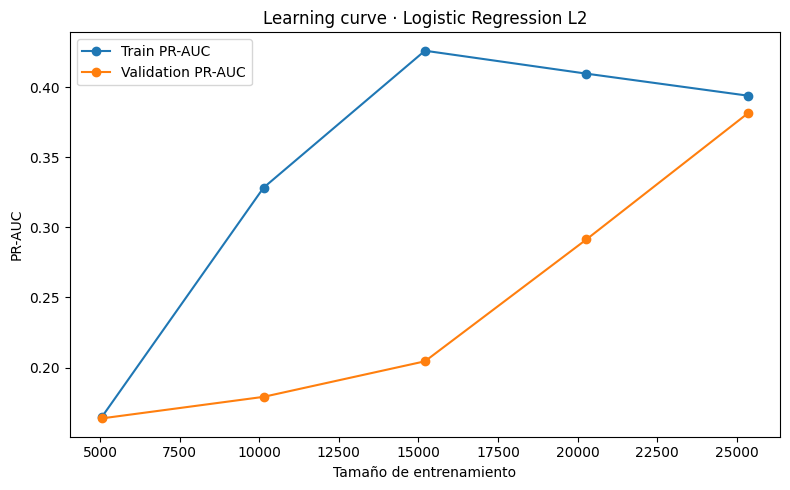

In [14]:
if RUN_DIAGNOSTIC_CURVES:
    diag_model = Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(
            penalty="l2", solver="lbfgs", class_weight="balanced",
            max_iter=2000, random_state=RANDOM_STATE
        ))
    ])

    train_sizes, train_scores, val_scores = learning_curve(
        diag_model,
        X_subtrain,
        y_subtrain,
        cv=cv_splits_subtrain,
        scoring="average_precision",
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=N_JOBS_CV,
        shuffle=False,
    )

    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Train PR-AUC")
    plt.plot(train_sizes, val_scores.mean(axis=1), marker="o", label="Validation PR-AUC")
    plt.xlabel("Tamaño de entrenamiento")
    plt.ylabel("PR-AUC")
    plt.title("Learning curve · Logistic Regression L2")
    plt.legend()
    plt.tight_layout()
    plt.show()

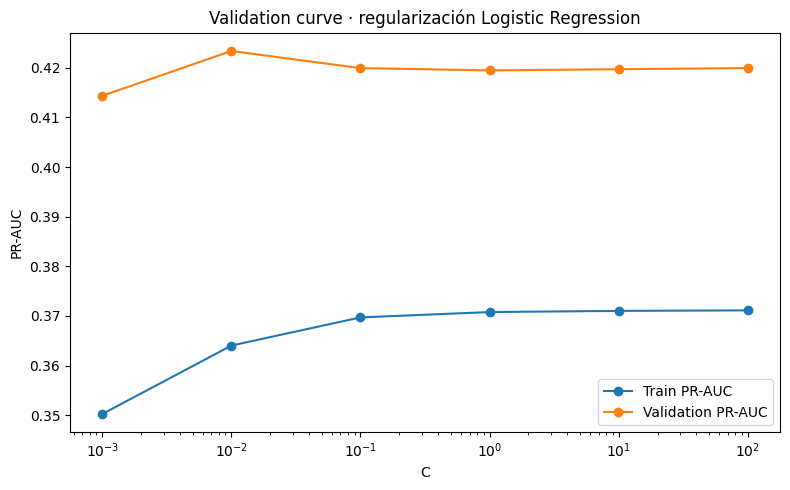

In [15]:
if RUN_DIAGNOSTIC_CURVES:
    c_range = np.logspace(-3, 2, 6)
    val_model = Pipeline([
        ("prep", make_preprocessor()),
        ("clf", LogisticRegression(
            penalty="l2", solver="lbfgs", class_weight="balanced",
            max_iter=2000, random_state=RANDOM_STATE
        ))
    ])

    tr_scores, va_scores = validation_curve(
        val_model,
        X_subtrain,
        y_subtrain,
        param_name="clf__C",
        param_range=c_range,
        cv=cv_splits_subtrain,
        scoring="average_precision",
        n_jobs=N_JOBS_CV,
    )

    plt.figure(figsize=(8, 5))
    plt.semilogx(c_range, tr_scores.mean(axis=1), marker="o", label="Train PR-AUC")
    plt.semilogx(c_range, va_scores.mean(axis=1), marker="o", label="Validation PR-AUC")
    plt.xlabel("C")
    plt.ylabel("PR-AUC")
    plt.title("Validation curve · regularización Logistic Regression")
    plt.legend()
    plt.tight_layout()
    plt.show()

# U6 · Ensembles, calibración temporal OOF y modelo en dos niveles

Los ensembles se comparan en **validation 2016** después de entrenarse exclusivamente con 2008–2015. La decisión documentada que debe reproducir el dashboard es **Random Forest** como modelo base.

La calibración final no usa folds aleatorios: se construyen predicciones OOF temporales expanding para 2013, 2014, 2015 y 2016; Platt se ajusta sobre `logit(p_raw)` de esas predicciones y después se aplica al modelo refiteado con 2008–2016.


In [16]:
# ============================================================
# U6 · ENSEMBLES evaluados en validation 2016
# ============================================================
try:
    bagging_clf = BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1,
    )
except TypeError:
    bagging_clf = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1,
    )

lr_vote = LogisticRegression(C=grid.best_params_["clf__C"], penalty="l2", solver="lbfgs", class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)
dt_vote = DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE)
gb_vote = GradientBoostingClassifier(n_estimators=160, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)

ensemble_models = {
    "Bagging": Pipeline([("prep", make_preprocessor(sparse=True)), ("clf", bagging_clf)]),
    "RandomForest": rf_final,
    "GradientBoosting": Pipeline([("prep", make_preprocessor(sparse=True)), ("clf", gb_vote)]),
    "Voting_soft": Pipeline([
        ("prep", make_preprocessor(sparse=True)),
        ("clf", VotingClassifier(
            estimators=[("lr", clone(lr_vote)), ("dt", clone(dt_vote)), ("gb", clone(gb_vote))],
            voting="soft", n_jobs=N_JOBS_CV,
        )),
    ]),
}

for name, model in ensemble_models.items():
    print("\n" + "=" * 70)
    print("MODELO:", name)
    if name == "RandomForest":
        fitted = model
    else:
        model.fit(X_subtrain, y_subtrain)
        fitted = model
    row, p = evaluate_classifier(name, fitted, X_validation, y_validation)
    classification_rows.append(row)
    fitted_models[name] = fitted
    pred_store[name] = p
    display(pd.DataFrame([row]))

# Stacking temporal manual: evita CV aleatoria dentro del meta-modelo.
if RUN_STACKING:
    base_factories = {
        "lr": lambda: Pipeline([("prep", make_preprocessor()), ("clf", clone(lr_vote))]),
        "dt": lambda: Pipeline([("prep", make_preprocessor()), ("clf", clone(dt_vote))]),
        "gb": lambda: Pipeline([("prep", make_preprocessor()), ("clf", clone(gb_vote))]),
    }
    oof_stack = np.full((len(subtrain_df), len(base_factories)), np.nan)
    for tr_idx, va_idx in cv_splits_subtrain:
        for j, factory in enumerate(base_factories.values()):
            m = factory()
            m.fit(X_subtrain.iloc[tr_idx], y_subtrain.iloc[tr_idx])
            oof_stack[va_idx, j] = m.predict_proba(X_subtrain.iloc[va_idx])[:, 1]
    stack_mask = np.isfinite(oof_stack).all(axis=1)
    meta_stack = LogisticRegression(penalty="l2", solver="lbfgs", class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)
    meta_stack.fit(oof_stack[stack_mask], y_subtrain.iloc[np.flatnonzero(stack_mask)])

    stack_val_features = []
    for factory in base_factories.values():
        m = factory()
        m.fit(X_subtrain, y_subtrain)
        stack_val_features.append(m.predict_proba(X_validation)[:, 1])
    p_stack = meta_stack.predict_proba(np.column_stack(stack_val_features))[:, 1]
    row_stack = evaluate_probabilities("Stacking_temporal", y_validation, p_stack)
    classification_rows.append(row_stack)
    pred_store["Stacking_temporal"] = p_stack
    display(pd.DataFrame([row_stack]))

classification_results = (
    pd.DataFrame(classification_rows)
    .drop_duplicates(subset="model", keep="last")
    .sort_values(["pr_auc", "lift_top_1pct"], ascending=False)
    .reset_index(drop=True)
)
print("\nCOMPARACIÓN GLOBAL · VALIDATION 2016")
display(classification_results)



MODELO: Bagging


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,Bagging,0.830764,0.521151,0.311782,0.821192,0.451966,4.709674,3.713408,0.17446



MODELO: RandomForest


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,RandomForest,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.69451,0.159051



MODELO: GradientBoosting


...


MODELO: Voting_soft


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,Voting_soft,0.834977,0.528094,0.484776,0.572375,0.524946,4.709674,3.741754,0.135319


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,Stacking_temporal,0.834975,0.528118,0.351375,0.773888,0.483309,4.898061,3.760652,0.17317



COMPARACIÓN GLOBAL · VALIDATION 2016


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,RandomForest,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.694510,0.159051
1,GradientBoosting,0.834703,0.531686,0.722222,0.270577,0.393668,4.803867,3.741754,0.105146
2,Stacking_temporal,0.834975,0.528118,0.351375,0.773888,0.483309,4.898061,3.760652,0.173170
3,Voting_soft,0.834977,0.528094,0.484776,0.572375,0.524946,4.709674,3.741754,0.135319
4,Bagging,0.830764,0.521151,0.311782,0.821192,0.451966,4.709674,3.713408,0.174460
5,KNN_conditional,0.809988,0.505236,0.681548,0.216651,0.328787,4.521287,3.543328,0.108549
6,DecisionTree,0.826020,0.496565,0.328150,0.778619,0.461711,4.709674,3.685061,0.177783
7,Logistic_L1,0.812829,0.490953,0.323577,0.753075,0.452659,4.521287,3.486635,0.196082
8,Logistic_ElasticNet,0.812752,0.490712,0.323577,0.753075,0.452659,4.615480,3.467737,0.196075
9,Logistic_L2,0.812545,0.490113,0.323577,0.753075,0.452659,4.521287,3.467737,0.195953


In [17]:
if RUN_XGBOOST_IF_AVAILABLE:
    try:
        from xgboost import XGBClassifier
        n_pos = max(1, int(y_subtrain.sum()))
        n_neg = int(len(y_subtrain) - n_pos)
        scale_pos_weight = n_neg / n_pos

        xgb_model = Pipeline([
            ("prep", make_preprocessor()),
            ("clf", XGBClassifier(
                n_estimators=300, max_depth=5, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1,
            )),
        ])
        xgb_model.fit(X_subtrain, y_subtrain)
        row, p = evaluate_classifier("XGBoost", xgb_model, X_validation, y_validation)
        classification_rows.append(row)
        fitted_models["XGBoost"] = xgb_model
        pred_store["XGBoost"] = p
        print("XGBoost ejecutado sobre subtrain y evaluado en validation 2016.")
    except Exception as ex:
        print("XGBoost omitido:", ex)


XGBoost ejecutado sobre subtrain y evaluado en validation 2016.


In [18]:
classification_results = (
    pd.DataFrame(classification_rows)
    .drop_duplicates(subset="model", keep="last")
    .sort_values(["pr_auc", "lift_top_1pct"], ascending=False)
    .reset_index(drop=True)
)
display(classification_results)

ranked_best = str(classification_results.iloc[0]["model"])
print("Mejor candidato por PR-AUC en validation 2016:", ranked_best)

# El experimento estricto que alimenta el dashboard seleccionó RandomForest.
# No lo imponemos silenciosamente: exigimos que la selección de 2016 lo reproduzca.
if ranked_best != "RandomForest":
    raise AssertionError(
        "La selección en validation 2016 no reproduce el modelo base del dashboard. "
        f"Se obtuvo {ranked_best!r} y se esperaba 'RandomForest'. "
        "Revisar datos, versiones o hiperparámetros antes de abrir 2017."
    )

SELECTED_BASE_MODEL_NAME = ranked_best
print("Modelo base congelado:", SELECTED_BASE_MODEL_NAME)


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,RandomForest,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.694510,0.159051
1,XGBoost,0.848825,0.546199,0.337481,0.846736,0.482610,4.898061,3.713408,0.173439
2,GradientBoosting,0.834703,0.531686,0.722222,0.270577,0.393668,4.803867,3.741754,0.105146
3,Stacking_temporal,0.834975,0.528118,0.351375,0.773888,0.483309,4.898061,3.760652,0.173170
4,Voting_soft,0.834977,0.528094,0.484776,0.572375,0.524946,4.709674,3.741754,0.135319
5,Bagging,0.830764,0.521151,0.311782,0.821192,0.451966,4.709674,3.713408,0.174460
6,KNN_conditional,0.809988,0.505236,0.681548,0.216651,0.328787,4.521287,3.543328,0.108549
7,DecisionTree,0.826020,0.496565,0.328150,0.778619,0.461711,4.709674,3.685061,0.177783
8,Logistic_L1,0.812829,0.490953,0.323577,0.753075,0.452659,4.521287,3.486635,0.196082
9,Logistic_ElasticNet,0.812752,0.490712,0.323577,0.753075,0.452659,4.615480,3.467737,0.196075


Mejor candidato por PR-AUC en validation 2016: RandomForest
Modelo base congelado: RandomForest


In [19]:
# ============================================================
# CALIBRACIÓN PLATT TEMPORAL OOF · SIN TOCAR TEST 2017
# ============================================================
def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-8, 1 - 1e-8)
    return np.log(p / (1 - p)).reshape(-1, 1)

PLATT_OOF_YEARS = [2013, 2014, 2015, 2016]
p_oof_raw = np.full(len(train_df), np.nan, dtype=float)
platt_fold_rows = []

for val_year in PLATT_OOF_YEARS:
    tr_idx = np.flatnonzero(train_df["year"].to_numpy() < val_year)
    va_idx = np.flatnonzero(train_df["year"].to_numpy() == val_year)
    if len(tr_idx) == 0 or len(va_idx) == 0:
        raise ValueError(f"No hay datos suficientes para el fold Platt {val_year}.")
    fold_model = make_selected_rf_pipeline()
    fold_model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    p_oof_raw[va_idx] = fold_model.predict_proba(X_train.iloc[va_idx])[:, 1]
    platt_fold_rows.append({
        "train": f"{int(train_df.iloc[tr_idx]['year'].min())}-{int(train_df.iloc[tr_idx]['year'].max())}",
        "validation": val_year,
        "n_train": len(tr_idx),
        "n_validation": len(va_idx),
    })

oof_mask = np.isfinite(p_oof_raw)
OOF_ROWS_USED = int(oof_mask.sum())
print("Folds Platt:")
display(pd.DataFrame(platt_fold_rows))
print("Filas OOF usadas por Platt:", OOF_ROWS_USED)

# Platt sobre logit(p), como documenta la auditoría temporal estricta.
platt_model = LogisticRegression(C=1_000_000.0, solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE)
platt_model.fit(_logit(p_oof_raw[oof_mask]), y_train.iloc[np.flatnonzero(oof_mask)])
p_oof_cal = np.full(len(train_df), np.nan, dtype=float)
p_oof_cal[oof_mask] = platt_model.predict_proba(_logit(p_oof_raw[oof_mask]))[:, 1]

val_mask_dev = train_df["year"].to_numpy() == VALIDATION_YEAR
p_validation_raw = p_oof_raw[val_mask_dev]
p_validation_level1 = p_oof_cal[val_mask_dev]

raw_validation_metrics = evaluate_probabilities("RandomForest_raw_validation", y_validation, p_validation_raw)
level1_validation_metrics = evaluate_probabilities("Nivel1_Platt_validation", y_validation, p_validation_level1)

display(pd.DataFrame([raw_validation_metrics, level1_validation_metrics]))
print("Brier raw validation:", raw_validation_metrics["brier"])
print("Brier Nivel 1 validation:", level1_validation_metrics["brier"])


Folds Platt:


,train,validation,n_train,n_validation
0,2008-2012,2013,31680,6348
1,2008-2013,2014,38028,6360
2,2008-2014,2015,44388,6360
3,2008-2015,2016,50748,6372


Filas OOF usadas por Platt: 25440


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,RandomForest_raw_validation,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.69451,0.159051
1,Nivel1_Platt_validation,0.847381,0.546662,0.706019,0.288553,0.409671,5.086447,3.69451,0.102581


Brier raw validation: 0.15905102158391862
Brier Nivel 1 validation: 0.10258062113027658


### Qué hace exactamente Platt aquí

1. Para cada año OOF se entrena un Random Forest **solo con años anteriores**.
2. Ese RF genera una probabilidad raw sobre un año que no ha visto.
3. Se concatenan las predicciones OOF.
4. Se transforma la probabilidad a `logit(p)`.
5. Una regresión logística casi sin regularización aprende:

\[
P_{cal} = \frac{1}{1+e^{-(a\,logit(p_{RF})+b)}}
\]

Los parámetros `a` y `b` se imprimen debajo. Esa es la calibración; no se limita a mostrar un Brier archivado.


In [20]:
# Parámetros realmente aprendidos por Platt
platt_a = float(platt_model.coef_.ravel()[0])
platt_b = float(platt_model.intercept_.ravel()[0])
print("Coeficiente a:", platt_a)
print("Intercepto b:", platt_b)
print(f"Fórmula: sigmoid({platt_a:.8f} * logit(p_RF) + {platt_b:.8f})")

platt_fold_detail = pd.DataFrame(platt_fold_rows)
platt_fold_detail["acumulado_oof"] = platt_fold_detail["n_validation"].cumsum()
display(platt_fold_detail)
print("OOF total calculado:", OOF_ROWS_USED)


Coeficiente a: 1.1045664570492568
Intercepto b: -1.6081635142879844
Fórmula: sigmoid(1.10456646 * logit(p_RF) + -1.60816351)


,train,validation,n_train,n_validation,acumulado_oof
0,2008-2012,2013,31680,6348,6348
1,2008-2013,2014,38028,6360,12708
2,2008-2014,2015,44388,6360,19068
3,2008-2015,2016,50748,6372,25440


OOF total calculado: 25440


## Nivel 2 · Modulador biológico estacional

Para decidir si se usa Nivel 2, el modulador mensual que se evalúa en **2016** se estima exclusivamente con **2008–2015**. Una vez congelada la decisión, se vuelve a estimar con **2008–2016** para producir el test final 2017.


In [21]:
train_season_selection = (
    subtrain_df.groupby("month")
    .agg(event_rate=("target_presence", "mean"), dvc_count=("dvc_count", "sum"), n=("target_presence", "size"))
)
overall_rate_subtrain = subtrain_df["target_presence"].mean()
train_season_selection["relative_risk"] = train_season_selection["event_rate"] / max(overall_rate_subtrain, 1e-12)
month_rr_selection = train_season_selection["relative_risk"].to_dict()

display(train_season_selection.sort_values("relative_risk", ascending=False))
expected_bio_months = {5, 6, 10, 11, 12}
top5_months = set(train_season_selection["relative_risk"].nlargest(5).index.astype(int))
print("Top 5 meses por RR en subtrain:", sorted(top5_months))
print("Solapamiento con ventanas biológicas del plan:", sorted(top5_months & expected_bio_months))


,event_rate,dvc_count,n,relative_risk
month,,,,
5,0.237881,2182,4229,1.708947
6,0.196737,1466,4229,1.413364
11,0.144006,824,4229,1.034541
7,0.136202,816,4229,0.978482
10,0.132655,727,4229,0.953001
1,0.131710,789,4229,0.946206
4,0.129581,751,4229,0.930917
8,0.125562,730,4229,0.902039
12,0.121305,691,4229,0.871461


Top 5 meses por RR en subtrain: [5, 6, 7, 10, 11]
Solapamiento con ventanas biológicas del plan: [5, 6, 10, 11]


In [22]:
def apply_monthly_odds_modulator(p_base, months, rr_map):
    p = np.clip(np.asarray(p_base, dtype=float), 1e-8, 1 - 1e-8)
    odds = p / (1 - p)
    rr = np.asarray([rr_map.get(int(m), 1.0) for m in months], dtype=float)
    adjusted_odds = odds * rr
    return adjusted_odds / (1 + adjusted_odds)

def best_f1_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    if len(thresholds) == 0:
        return 0.5
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[int(np.nanargmax(f1))])

# VALIDATION 2016
p_validation_level2 = apply_monthly_odds_modulator(
    p_validation_level1,
    validation_df["month"].to_numpy(),
    month_rr_selection,
)
level2_validation_metrics = evaluate_probabilities("Nivel2_validation", y_validation, p_validation_level2)
validation_summary = pd.DataFrame([
    raw_validation_metrics,
    level1_validation_metrics,
    level2_validation_metrics,
])
display(validation_summary)

if (level2_validation_metrics["pr_auc"] >= level1_validation_metrics["pr_auc"]
        and level2_validation_metrics["brier"] <= level1_validation_metrics["brier"]):
    SELECTED_OUTPUT_MODE = "Nivel2_validation"
    p_validation_selected = p_validation_level2
else:
    SELECTED_OUTPUT_MODE = "Nivel1_validation"
    p_validation_selected = p_validation_level1

if SELECTED_OUTPUT_MODE != "Nivel2_validation":
    raise AssertionError(
        "Validation 2016 no reproduce la selección Nivel 2 documentada por el dashboard."
    )

SELECTED_THRESHOLD = best_f1_threshold(y_validation, p_validation_selected)
print("Salida seleccionada antes de abrir 2017:", SELECTED_OUTPUT_MODE)
print("Umbral F1 congelado en validation 2016:", repr(SELECTED_THRESHOLD))

# REFIT FINAL 2008–2016
rf_final_development = make_selected_rf_pipeline()
rf_final_development.fit(X_train, y_train)

# TEST 2017: se abre una sola vez a partir de aquí.
p_test_raw = rf_final_development.predict_proba(X_test)[:, 1]
p_level1 = platt_model.predict_proba(_logit(p_test_raw))[:, 1]

train_season_final = (
    train_df.groupby("month")
    .agg(event_rate=("target_presence", "mean"), dvc_count=("dvc_count", "sum"), n=("target_presence", "size"))
)
overall_rate_development = train_df["target_presence"].mean()
train_season_final["relative_risk"] = train_season_final["event_rate"] / max(overall_rate_development, 1e-12)
month_rr_final = train_season_final["relative_risk"].to_dict()

p_level2 = apply_monthly_odds_modulator(p_level1, test_df["month"].to_numpy(), month_rr_final)
p_final = p_level2.copy()

level1_metrics = evaluate_probabilities("Nivel1_test_2017", y_test, p_level1, threshold=SELECTED_THRESHOLD)
level2_metrics = evaluate_probabilities("Nivel2_test_2017", y_test, p_level2, threshold=SELECTED_THRESHOLD)
display(pd.DataFrame([level1_metrics, level2_metrics]))


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,RandomForest_raw_validation,0.847381,0.546662,0.365351,0.788079,0.499251,5.086447,3.694510,0.159051
1,Nivel1_Platt_validation,0.847381,0.546662,0.706019,0.288553,0.409671,5.086447,3.694510,0.102581
2,Nivel2_validation,0.853665,0.571962,0.707048,0.303690,0.424884,5.369028,3.855141,0.100342


Salida seleccionada antes de abrir 2017: Nivel2_validation
Umbral F1 congelado en validation 2016: 0.2500548716065739


,model,roc_auc,pr_auc,precision_050,recall_050,f1_050,lift_top_1pct,lift_top_10pct,brier
0,Nivel1_test_2017,0.846317,0.598075,0.513393,0.602094,0.554217,5.125818,3.895633,0.105321
1,Nivel2_test_2017,0.852175,0.616801,0.515129,0.609075,0.558177,5.299575,4.052504,0.103348


### Cálculo explícito de las métricas que aparecen en el frontend

Las métricas siguientes se vuelven a calcular directamente desde `y_test` y `p_final`.  
Las dependientes del umbral utilizan **exactamente el umbral seleccionado en 2016**.


In [23]:
def metricas_frontend_reto5(y_true, score, threshold):
    y_arr = np.asarray(y_true, dtype=int)
    s = np.asarray(score, dtype=float)
    pred = (s >= float(threshold)).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_arr, pred, labels=[0,1]).ravel()
    base_rate = float(y_arr.mean())

    def lift(frac):
        n_top = max(1, int(np.ceil(len(s) * frac)))
        idx = np.argsort(s)[-n_top:]
        return float(y_arr[idx].mean() / base_rate)

    return {
        "roc_auc": float(roc_auc_score(y_arr, s)),
        "pr_auc": float(average_precision_score(y_arr, s)),
        "brier": float(brier_score_loss(y_arr, s)),
        "lift_top_1pct": lift(0.01),
        "lift_top_10pct": lift(0.10),
        "threshold": float(threshold),
        "precision": float(precision_score(y_arr, pred, zero_division=0)),
        "recall": float(recall_score(y_arr, pred, zero_division=0)),
        "f1": float(f1_score(y_arr, pred, zero_division=0)),
        "accuracy": float((tp + tn) / len(y_arr)),
        "specificity": float(tn / (tn + fp)),
        "false_positive_rate": float(fp / (tn + fp)),
        "false_negative_rate": float(fn / (tp + fn)),
        "alerts": int(pred.sum()),
        "alert_rate": float(pred.mean()),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "rows": int(len(y_arr)),
        "positives": int(y_arr.sum()),
        "negatives": int((y_arr == 0).sum()),
    }

metricas_test_recalculadas = metricas_frontend_reto5(y_test, p_final, SELECTED_THRESHOLD)
display(pd.DataFrame([metricas_test_recalculadas]).T.rename(columns={0:"valor"}))


,valor
roc_auc,0.852175
pr_auc,0.616801
brier,0.103348
lift_top_1pct,5.299575
lift_top_10pct,4.052504
threshold,0.250055
precision,0.515129
recall,0.609075
f1,0.558177
accuracy,0.826585


## Curvas de evaluación · test final 2017

Las siguientes figuras son **descriptivas** del test final. No se utilizan para cambiar modelo, calibración, modulador ni umbral.


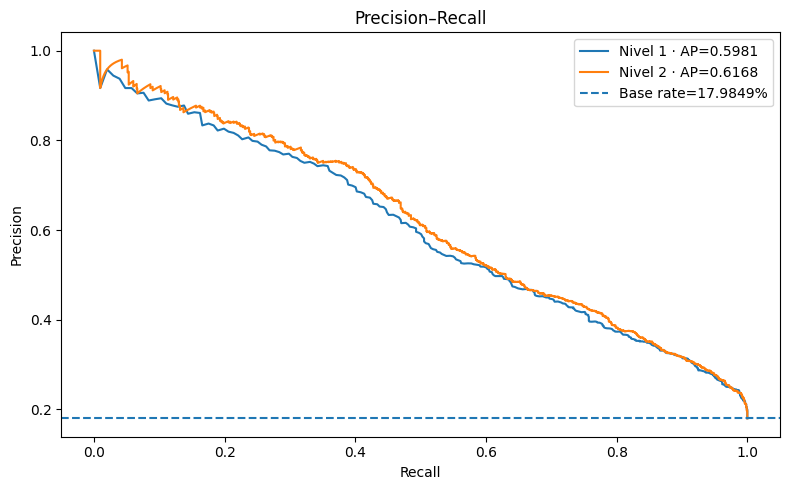

In [24]:
precision1, recall1, _ = precision_recall_curve(y_test, p_level1)
precision2, recall2, _ = precision_recall_curve(y_test, p_level2)

plt.figure(figsize=(8, 5))
plt.plot(recall1, precision1, label=f"Nivel 1 · AP={average_precision_score(y_test, p_level1):.4f}")
plt.plot(recall2, precision2, label=f"Nivel 2 · AP={average_precision_score(y_test, p_level2):.4f}")
plt.axhline(y_test.mean(), linestyle="--", label=f"Base rate={y_test.mean():.4%}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall")
plt.legend()
plt.tight_layout()
plt.show()

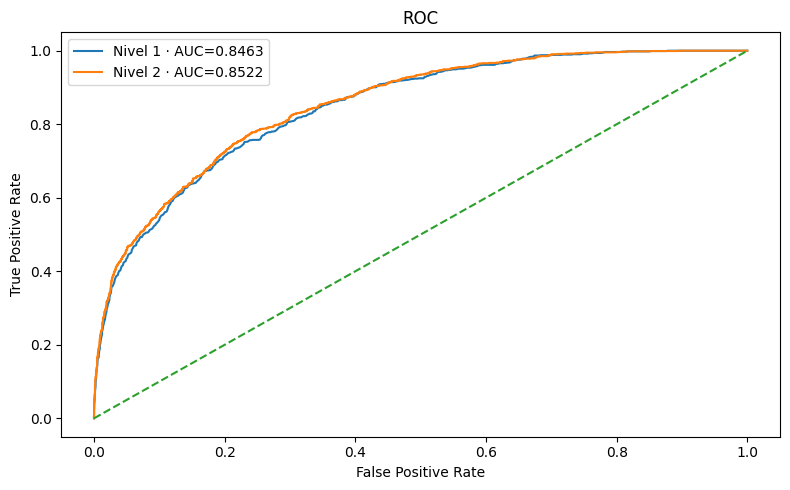

In [25]:
fpr1, tpr1, _ = roc_curve(y_test, p_level1)
fpr2, tpr2, _ = roc_curve(y_test, p_level2)

plt.figure(figsize=(8, 5))
plt.plot(fpr1, tpr1, label=f"Nivel 1 · AUC={roc_auc_score(y_test, p_level1):.4f}")
plt.plot(fpr2, tpr2, label=f"Nivel 2 · AUC={roc_auc_score(y_test, p_level2):.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC")
plt.legend()
plt.tight_layout()
plt.show()

<Figure size 600x500 with 0 Axes>

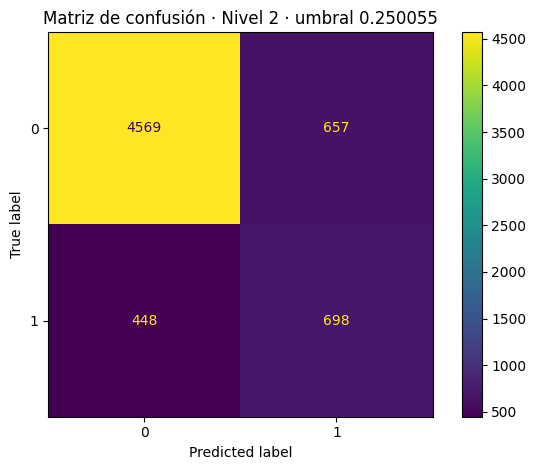

{'TP': 698, 'FP': 657, 'TN': 4569, 'FN': 448}


In [26]:
pred_level2_selected = (p_level2 >= SELECTED_THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred_level2_selected)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(cm)
disp.plot(values_format="d")
plt.title(f"Matriz de confusión · Nivel 2 · umbral {SELECTED_THRESHOLD:.6f}")
plt.tight_layout()
plt.show()

TN, FP, FN, TP = cm.ravel()
print({"TP": int(TP), "FP": int(FP), "TN": int(TN), "FN": int(FN)})


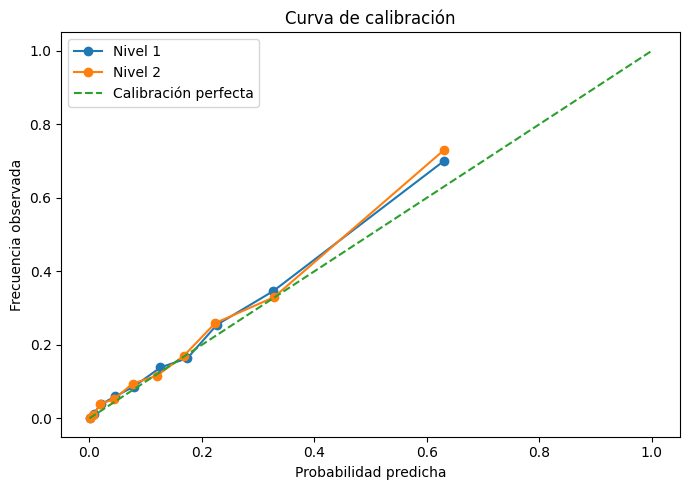

In [27]:
prob_true1, prob_pred1 = calibration_curve(y_test, p_level1, n_bins=10, strategy="quantile")
prob_true2, prob_pred2 = calibration_curve(y_test, p_level2, n_bins=10, strategy="quantile")

plt.figure(figsize=(7, 5))
plt.plot(prob_pred1, prob_true1, marker="o", label="Nivel 1")
plt.plot(prob_pred2, prob_true2, marker="o", label="Nivel 2")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibración perfecta")
plt.xlabel("Probabilidad predicha")
plt.ylabel("Frecuencia observada")
plt.title("Curva de calibración")
plt.legend()
plt.tight_layout()
plt.show()

# U7 · Regresión y modelos de conteo

Se mantienen los mismos modelos del notebook original. La **selección** del modelo de conteo se realiza en validation 2016 tras entrenar con 2008–2015. Después se refitea con 2008–2016 y se evalúa una sola vez en 2017.


In [28]:
COUNT_NUMERIC = ["year", "count_points", "easting_mean", "northing_mean", "month_sin", "month_cos"]
COUNT_CATEGORICAL = ["road_category", "local_authority_name"]
COUNT_FEATURES = COUNT_NUMERIC + COUNT_CATEGORICAL

Xr_subtrain = subtrain_df[COUNT_FEATURES].copy()
Xr_validation = validation_df[COUNT_FEATURES].copy()
Xr_train = train_df[COUNT_FEATURES].copy()
Xr_test = test_df[COUNT_FEATURES].copy()
yr_subtrain = subtrain_df["dvc_count"].astype(float).copy()
yr_validation = validation_df["dvc_count"].astype(float).copy()
yr_train = train_df["dvc_count"].astype(float).copy()
yr_test = test_df["dvc_count"].astype(float).copy()

def make_count_preprocessor():
    return make_preprocessor(COUNT_NUMERIC, COUNT_CATEGORICAL, sparse=True)

def eval_regression(name, y_true, pred):
    pred = np.asarray(pred, dtype=float)
    pred_nonneg = np.clip(pred, 1e-9, None)
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "R2": r2_score(y_true, pred),
        "PoissonDeviance": mean_poisson_deviance(y_true, pred_nonneg),
    }

reg_models = {
    "LinearRegression": Pipeline([("prep", make_count_preprocessor()), ("reg", LinearRegression())]),
    "Ridge": Pipeline([("prep", make_count_preprocessor()), ("reg", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("prep", make_count_preprocessor()), ("reg", Lasso(alpha=0.001, max_iter=5000, random_state=RANDOM_STATE))]),
}

reg_rows = []
reg_pred_validation = {}
for name, model in reg_models.items():
    print("Ajustando en subtrain:", name)
    model.fit(Xr_subtrain, yr_subtrain)
    p = model.predict(Xr_validation)
    reg_rows.append(eval_regression(name, yr_validation, p))
    reg_pred_validation[name] = p

svr_idx = capped_stratified_indices((yr_subtrain > 0).astype(int), MAX_ROWS_SVR)
svr_model = Pipeline([("prep", make_count_preprocessor()), ("reg", SVR(C=5.0, epsilon=0.05, kernel="rbf"))])
print("Ajustando SVR con", len(svr_idx), "filas de subtrain")
svr_model.fit(Xr_subtrain.iloc[svr_idx], yr_subtrain.iloc[svr_idx])
svr_p = svr_model.predict(Xr_validation)
reg_rows.append(eval_regression("SVR_candidate", yr_validation, svr_p))
reg_pred_validation["SVR_candidate"] = svr_p

display(pd.DataFrame(reg_rows).sort_values("MAE"))


Ajustando en subtrain: LinearRegression
Ajustando en subtrain: Ridge
Ajustando en subtrain: Lasso
Ajustando SVR con 30000 filas de subtrain


,model,MAE,RMSE,R2,PoissonDeviance
3,SVR_candidate,0.268705,0.673999,0.303143,1.181669
2,Lasso,0.352449,0.714824,0.216168,0.754296
1,Ridge,0.352725,0.713431,0.219219,0.788984
0,LinearRegression,0.352733,0.713441,0.219198,0.793137


## Poisson y Negative Binomial con offset

El offset es `log(exposure_vkm_proxy)`. Esta exposición es una **aproximación operativa** construida con AADF, longitud y días del mes; no debe confundirse con kilómetros reales recorridos por cada vehículo.

Para el GLM no se incluyen `traffic_mean` ni `link_length_km` como predictores directos porque ya forman parte del offset.

In [29]:
def _fit_glm_robust(endog, exog, family, offset):
    clean_offset = np.nan_to_num(offset, nan=0.0, posinf=20.0, neginf=-20.0)
    clean_exog = np.clip(exog, -15.0, 15.0)
    for method in [None, "bfgs", "cg", "nm"]:
        try:
            model = sm.GLM(endog, clean_exog, family=family, offset=clean_offset)
            res = model.fit(maxiter=200) if method is None else model.fit(method=method, maxiter=200)
            if hasattr(res, "params") and np.all(np.isfinite(res.params)):
                return res
        except Exception:
            continue
    return sm.GLM(endog, clean_exog, family=sm.families.Poisson(), offset=clean_offset).fit(maxiter=200)

def fit_count_glm(train_frame, eval_frame, family):
    idx = np.arange(len(train_frame))
    if len(idx) > MAX_ROWS_GLM:
        idx = capped_stratified_indices((train_frame["dvc_count"] > 0).astype(int), MAX_ROWS_GLM)
    fit_df = train_frame.iloc[idx].copy()

    prep = make_preprocessor(COUNT_NUMERIC, COUNT_CATEGORICAL, sparse=False)
    X_fit_t = prep.fit_transform(fit_df[COUNT_FEATURES])
    X_eval_t = prep.transform(eval_frame[COUNT_FEATURES])
    X_fit_sm = sm.add_constant(X_fit_t, has_constant="add")
    X_eval_sm = sm.add_constant(X_eval_t, has_constant="add")

    result = _fit_glm_robust(
        fit_df["dvc_count"].astype(float).to_numpy(),
        X_fit_sm,
        family,
        fit_df["log_exposure"].astype(float).to_numpy(),
    )
    pred = result.predict(X_eval_sm, offset=eval_frame["log_exposure"].astype(float).to_numpy())
    return result, np.asarray(pred, dtype=float), prep

def manual_bic(result):
    k = len(result.params)
    n = result.nobs
    return -2 * result.llf + k * np.log(n)

# Selección en validation 2016.
poisson_glm_val, poisson_pred_val, glm_prep_val = fit_count_glm(subtrain_df, validation_df, sm.families.Poisson())
nb_glm_val, nb_pred_val, _ = fit_count_glm(subtrain_df, validation_df, sm.families.NegativeBinomial(alpha=1.0))
reg_rows.append(eval_regression("Poisson_offset", yr_validation, poisson_pred_val))
reg_rows.append(eval_regression("NegativeBinomial_offset", yr_validation, nb_pred_val))

validation_reg_results = pd.DataFrame(reg_rows).drop_duplicates("model", keep="last").sort_values("PoissonDeviance")
display(validation_reg_results)

aic_bic_validation = pd.DataFrame([
    {"model": "Poisson_offset", "AIC": poisson_glm_val.aic, "BIC": manual_bic(poisson_glm_val), "logLik": poisson_glm_val.llf, "nobs": poisson_glm_val.nobs},
    {"model": "NegativeBinomial_offset", "AIC": nb_glm_val.aic, "BIC": manual_bic(nb_glm_val), "logLik": nb_glm_val.llf, "nobs": nb_glm_val.nobs},
]).sort_values("AIC")
display(aic_bic_validation)

SELECTED_COUNT_MODEL = str(validation_reg_results.iloc[0]["model"])
if SELECTED_COUNT_MODEL != "Poisson_offset":
    raise AssertionError(
        "Validation 2016 no reproduce Poisson_offset como modelo de conteo seleccionado. "
        f"Se obtuvo {SELECTED_COUNT_MODEL}."
    )
print("Modelo de conteo congelado antes de test:", SELECTED_COUNT_MODEL)

# Refit 2008–2016 y evaluación final 2017.
poisson_glm, poisson_pred, glm_prep = fit_count_glm(train_df, test_df, sm.families.Poisson())
nb_glm, nb_pred, _ = fit_count_glm(train_df, test_df, sm.families.NegativeBinomial(alpha=1.0))
reg_test_rows = [
    eval_regression("Poisson_offset_test_2017", yr_test, poisson_pred),
    eval_regression("NegativeBinomial_offset_test_2017_posthoc", yr_test, nb_pred),
]
display(pd.DataFrame(reg_test_rows))

aic_bic = pd.DataFrame([
    {"model": "Poisson_offset_development", "AIC": poisson_glm.aic, "BIC": manual_bic(poisson_glm), "logLik": poisson_glm.llf, "nobs": poisson_glm.nobs},
    {"model": "NegativeBinomial_offset_development", "AIC": nb_glm.aic, "BIC": manual_bic(nb_glm), "logLik": nb_glm.llf, "nobs": nb_glm.nobs},
]).sort_values("AIC")
display(aic_bic)


,model,MAE,RMSE,R2,PoissonDeviance
4,Poisson_offset,0.321192,0.670251,0.310872,0.709394
5,NegativeBinomial_offset,0.328258,0.680408,0.289828,0.717398
2,Lasso,0.352449,0.714824,0.216168,0.754296
1,Ridge,0.352725,0.713431,0.219219,0.788984
0,LinearRegression,0.352733,0.713441,0.219198,0.793137
3,SVR_candidate,0.268705,0.673999,0.303143,1.181669


,model,AIC,BIC,logLik,nobs
1,NegativeBinomial_offset,51143.315625,51536.039234,-25529.657812,50748
0,Poisson_offset,53190.871617,53583.595227,-26553.435809,50748


Modelo de conteo congelado antes de test: Poisson_offset


,model,MAE,RMSE,R2,PoissonDeviance
0,Poisson_offset_test_2017,0.340250,0.696553,0.343920,0.781316
1,NegativeBinomial_offset_test_2017_posthoc,0.346117,0.707637,0.322876,0.788961


,model,AIC,BIC,logLik,nobs
1,NegativeBinomial_offset_development,57861.692133,58259.620155,-28888.846066,57120
0,Poisson_offset_development,60090.125450,60488.053472,-30003.062725,57120


## Diagnóstico de residuos

Se muestran residuos de Pearson del Poisson frente a la predicción. La finalidad es detectar patrones sistemáticos, heterocedasticidad extrema o segmentos donde el modelo de conteo sea insuficiente.

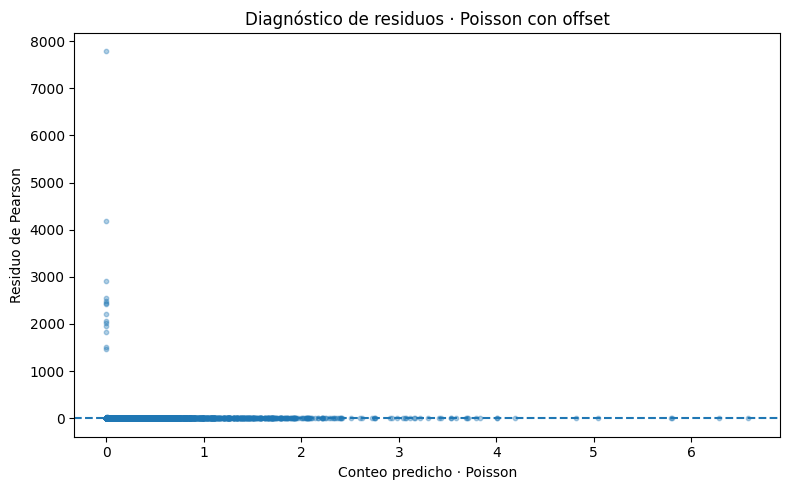

In [30]:
pearson_resid_test = (
    yr_test.to_numpy() - poisson_pred
) / np.sqrt(np.clip(poisson_pred, 1e-9, None))

plt.figure(figsize=(8, 5))
plt.scatter(poisson_pred, pearson_resid_test, s=10, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.xlabel("Conteo predicho · Poisson")
plt.ylabel("Residuo de Pearson")
plt.title("Diagnóstico de residuos · Poisson con offset")
plt.tight_layout()
plt.show()

# U8 · Error por segmento, importancia de variables y exportación auditable

La importancia de variables se interpreta como **relevancia predictiva**, no como causalidad.

El análisis segmentado permite comprobar si una métrica global oculta fallos sistemáticos por tipo de carretera o autoridad local.

In [31]:
segment_df = test_df[
    ["cell", "year", "month", "road_category", "local_authority_name", "road_name",
     "target_presence", "dvc_count", "exposure_vkm_proxy"]
].copy()

segment_df["p_level1"] = p_level1
segment_df["p_level2"] = p_level2
segment_df["p_final"] = p_final
segment_df["pred_count_final"] = poisson_pred
segment_df["selected_classifier"] = SELECTED_BASE_MODEL_NAME
segment_df["selected_output_mode"] = SELECTED_OUTPUT_MODE
segment_df["selected_threshold"] = SELECTED_THRESHOLD
segment_df["selected_count_model"] = SELECTED_COUNT_MODEL
segment_df["class_abs_error"] = np.abs(segment_df["target_presence"] - segment_df["p_final"])
segment_df["count_abs_error"] = np.abs(segment_df["dvc_count"] - segment_df["pred_count_final"])

def safe_ap(g):
    if g["target_presence"].nunique() < 2:
        return np.nan
    return average_precision_score(g["target_presence"], g["p_final"])

error_by_road = (
    segment_df.groupby("road_category", dropna=False)
    .apply(lambda g: pd.Series({
        "n": len(g),
        "positive_rate": g["target_presence"].mean(),
        "PR_AUC": safe_ap(g),
        "mean_abs_prob_error": g["class_abs_error"].mean(),
        "MAE_count_poisson": g["count_abs_error"].mean(),
    }))
    .sort_values("mean_abs_prob_error", ascending=False)
)
display(error_by_road)


,n,positive_rate,PR_AUC,mean_abs_prob_error,MAE_count_poisson
road_category,,,,,
TA,1416.0,0.189972,0.414094,0.275110,0.399513
PA,4284.0,0.184641,0.680398,0.185432,0.331749
MCU,264.0,0.128788,0.274837,0.180632,0.208709
TM,60.0,0.300000,0.956096,0.170801,0.898098
MB,348.0,0.097701,0.452286,0.137701,0.207370


### Risk Response Score y marca del umbral en el gauge

El frontend **no usa `p_final × 100`** como score. Utiliza posición relativa dentro de 2017:

```python
risk_percentile = rank(p_final) / N * 100
```

Para dibujar el umbral probabilístico sobre esa misma escala se calcula el porcentaje de observaciones cuyo `p_final` es menor o igual al corte.


In [32]:
segment_df["risk_percentile"] = segment_df["p_final"].rank(method="average", pct=True) * 100.0

def empirical_threshold_percentile(scores, threshold):
    scores = np.asarray(scores, dtype=float)
    return float(np.mean(scores <= float(threshold)) * 100.0)

threshold_risk_score = empirical_threshold_percentile(segment_df["p_final"], SELECTED_THRESHOLD)
print("Umbral probabilístico:", SELECTED_THRESHOLD)
print("Posición equivalente en Risk Response Score:", threshold_risk_score)

display(
    segment_df[["cell","month","p_final","risk_percentile"]]
    .sort_values("p_final")
    .iloc[[0, len(segment_df)//2, -1]]
)


Umbral probabilístico: 0.2500548716065739
Posición equivalente en Risk Response Score: 78.73509102322662


,cell,month,p_final,risk_percentile
5126,6887,3,0.000056,0.015694
434,4669,3,0.097458,50.015694
1744,5306,5,0.971164,100.000000


,feature,importance
2,num__traffic_sum,0.230726
1,num__traffic_mean,0.227997
6,num__northing_mean,0.114639
4,num__count_points,0.107896
5,num__easting_mean,0.077113
3,num__link_length_km,0.068937
0,num__year,0.035118
10,cat__road_category_TA,0.017212
18,cat__local_authority_name_Comhairle nan Eilean...,0.015272
9,cat__road_category_PA,0.014781


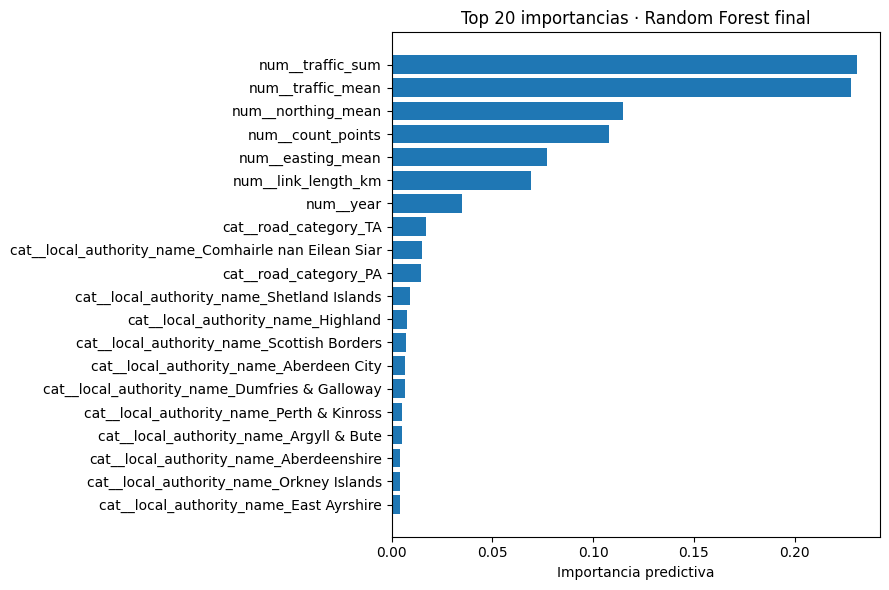

In [33]:
rf_fitted = rf_final_development
prep_rf = rf_fitted.named_steps["prep"]
clf_rf = rf_fitted.named_steps["clf"]
feature_names_rf = prep_rf.get_feature_names_out()
importance_df = (
    pd.DataFrame({"feature": feature_names_rf, "importance": clf_rf.feature_importances_})
    .sort_values("importance", ascending=False)
    .head(20)
)
display(importance_df)

plt.figure(figsize=(9, 6))
plot_df = importance_df.sort_values("importance", ascending=True)
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("Importancia predictiva")
plt.title("Top 20 importancias · Random Forest final")
plt.tight_layout()
plt.show()


In [34]:
claims_obs = claims.copy()
if "cost_observed" in claims_obs.columns:
    claims_obs = claims_obs[claims_obs["cost_observed"].eq(True)].copy()

if {"year", "avg_claim_cost_gbp"}.issubset(claims_obs.columns) and len(claims_obs) >= 2:
    claims_obs = claims_obs.dropna(subset=["year", "avg_claim_cost_gbp"]).sort_values("year")
    x_year = claims_obs["year"].astype(float).to_numpy()
    y_cost = claims_obs["avg_claim_cost_gbp"].astype(float).to_numpy()
    slope, intercept = np.polyfit(x_year, np.log(y_cost), 1)
    TARGET_COST_YEAR = int(np.nanmax(x_year)) + 2
    AVG_CLAIM_COST_GBP = float(np.exp(intercept + slope * TARGET_COST_YEAR))
elif "avg_claim_cost_gbp" in claims_obs.columns and len(claims_obs):
    TARGET_COST_YEAR = int(TEST_YEAR)
    AVG_CLAIM_COST_GBP = float(claims_obs["avg_claim_cost_gbp"].dropna().iloc[-1])
else:
    TARGET_COST_YEAR = int(TEST_YEAR)
    AVG_CLAIM_COST_GBP = np.nan

segment_df["expected_claim_cost_gbp"] = segment_df["p_final"] * AVG_CLAIM_COST_GBP
segment_df["expected_savings_gbp"] = segment_df["expected_claim_cost_gbp"] * REDUCTION_ASSUMED
segment_df["actual_presence"] = segment_df["target_presence"]
segment_df["actual_count"] = segment_df["dvc_count"]

EXPORT_CSV = ARTIFACT_DIR / "predicciones_test_2017.csv"
segment_df.to_csv(EXPORT_CSV, index=False)

# Resumen de clasificación compatible con el dashboard.
classification_test_export = pd.DataFrame([
    {**level1_metrics, "evaluation_set": "test_2017", "selection_eligible": False},
    {**level2_metrics, "evaluation_set": "test_2017", "selection_eligible": False},
    {**level2_metrics, "model": "Sistema_final_test_2017", "evaluation_set": "test_2017", "selection_eligible": False},
])
classification_test_export.to_csv(ARTIFACT_DIR / "clasificacion_test_2017.csv", index=False)

train_season_final.reset_index()[["month", "event_rate", "dvc_count", "n", "relative_risk"]].to_csv(
    ARTIFACT_DIR / "modulador_mensual_final_2008_2016.csv", index=False
)

metadata_temporal = {
    "protocol": {
        "subtrain": "2008-2015", "validation": 2016, "development_refit": "2008-2016",
        "test": 2017, "excluded": [2018], "cv": "expanding_temporal_only",
    },
    "classification": {
        "selected_base_model": SELECTED_BASE_MODEL_NAME,
        "selected_output_mode": SELECTED_OUTPUT_MODE,
        "selected_threshold_from_validation": float(SELECTED_THRESHOLD),
    },
    "count": {"selected_model": SELECTED_COUNT_MODEL},
}
with open(ARTIFACT_DIR / "metadata_reto5_temporal.json", "w", encoding="utf-8") as f:
    json.dump(metadata_temporal, f, indent=2, ensure_ascii=False)

print("CSV auditable:", EXPORT_CSV.resolve())
print("Coste medio usado:", AVG_CLAIM_COST_GBP, "| año de referencia:", TARGET_COST_YEAR)
display(segment_df.sort_values("p_final", ascending=False).head(20))


CSV auditable: C:\Users\Gabriel\Documents\GitHub\IA\notebooks\escocia\artifacts\reto5\predicciones_test_2017.csv
Coste medio usado: 5529.8720237404 | año de referencia: 2026


,cell,year,month,road_category,local_authority_name,road_name,target_presence,dvc_count,exposure_vkm_proxy,p_level1,p_level2,p_final,pred_count_final,selected_classifier,selected_output_mode,selected_threshold,selected_count_model,class_abs_error,count_abs_error,risk_percentile,expected_claim_cost_gbp,expected_savings_gbp,actual_presence,actual_count
1744,5306,2017,5,PA,Glasgow City,M74,1,11,1.102390e+08,0.952007,0.971164,0.971164,6.582341,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.028836,4.417659,100.000000,5370.411844,1074.082369,1,11
1745,5306,2017,6,PA,Glasgow City,M74,1,9,1.066829e+08,0.952007,0.965368,0.965368,6.290266,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.034632,2.709734,99.984306,5338.361711,1067.672342,1,9
1960,5387,2017,5,TM,North Lanarkshire,M80,1,7,2.944334e+07,0.923066,0.953207,0.953207,1.627635,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.046793,5.372365,99.968613,5271.111658,1054.222332,1,7
1750,5306,2017,11,PA,Glasgow City,M74,1,4,1.066829e+08,0.952007,0.953080,0.953080,2.906614,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.046920,1.093386,99.952919,5270.408832,1054.081766,1,4
1746,5306,2017,7,PA,Glasgow City,M74,1,4,1.102390e+08,0.952007,0.951889,0.951889,5.797654,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.048111,1.797654,99.937225,5263.822696,1052.764539,1,4
1740,5306,2017,1,PA,Glasgow City,M74,1,2,1.102390e+08,0.952007,0.949391,0.949391,3.410011,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.050609,1.410011,99.921532,5250.009466,1050.001893,1,2
1749,5306,2017,10,PA,Glasgow City,M74,1,10,1.102390e+08,0.952007,0.949240,0.949240,3.294648,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.050760,6.705352,99.905838,5249.176686,1049.835337,1,10
1743,5306,2017,4,PA,Glasgow City,M74,1,6,1.066829e+08,0.952007,0.948551,0.948551,5.807091,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.051449,0.192909,99.890144,5245.367012,1049.073402,1,6
1747,5306,2017,8,PA,Glasgow City,M74,1,7,1.102390e+08,0.952007,0.947843,0.947843,4.816310,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.052157,2.183690,99.874451,5241.452503,1048.290501,1,7
1751,5306,2017,12,PA,Glasgow City,M74,1,6,1.102390e+08,0.952007,0.946703,0.946703,3.041576,RandomForest,Nivel2_validation,0.250055,Poisson_offset,0.053297,2.958424,99.858757,5235.144474,1047.028895,1,6


In [35]:
try:
    import joblib
    MODEL_FILE = ARTIFACT_DIR / "modelo_reto5_estricto_2017.joblib"
    joblib.dump({
        "base_model": rf_final_development,
        "platt_model": platt_model,
        "month_rr": month_rr_final,
        "threshold": float(SELECTED_THRESHOLD),
        "selected_output_mode": SELECTED_OUTPUT_MODE,
        "test_year": TEST_YEAR,
    }, MODEL_FILE)
    print("Modelo exportado:", MODEL_FILE.resolve())
except Exception as ex:
    print("No se pudo exportar el paquete con joblib:", ex)


Modelo exportado: C:\Users\Gabriel\Documents\GitHub\IA\notebooks\escocia\artifacts\reto5\modelo_reto5_estricto_2017.joblib


# U9 · Conexión con OpenStreetMap, cinemática e Insurtech

El plan de implementación exige conectar el aprendizaje supervisado con el motor telemático.

Se usa `OSMScotlandService.simulate_telematics_alert()` para obtener:

- nivel de triaje;
- especie dominante y severidad;
- atributos de vía;
- `risk_index`;
- condición crepuscular;
- distancia de parada actual y recomendada;
- **delta de distancia de frenado**;
- Safety Score;
- ahorro actuarial esperado.

> El plan menciona un **Risk Response Score**, pero los archivos entregados no definen una ecuación formal distinta. Por trazabilidad, este notebook **no inventa una fórmula nueva**: conserva por separado la probabilidad del modelo (`p_level2`) y el `risk_index` del simulador OSM. Ambos quedan disponibles para formalizar el score en una decisión posterior.

In [36]:
def load_osm_service():
    # 1) Estructura normal del proyecto
    try:
        from scripts.pipeline.osm_scotland import osm_service as service
        return service
    except Exception:
        pass

    # 2) Fallback: osm_scotland.py junto al notebook o en el padre.
    candidates = [
        Path.cwd() / "osm_scotland.py",
        Path.cwd().parent / "osm_scotland.py",
    ]
    for p in candidates:
        if p.exists():
            import importlib.util
            spec = importlib.util.spec_from_file_location("osm_scotland_local", p)
            module = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(module)
            return module.OSMScotlandService(
                mode="offline",
                cache_dir=ARTIFACT_DIR / "osm_cache",
                verbose=False,
            )
    return None

osm_service_reto5 = load_osm_service()
print("OSM disponible:", osm_service_reto5 is not None)

OSM disponible: True


In [37]:
def diagnostico_insurtech_desde_modelo(
    road_name: str,
    month: int,
    p_model_level2: float,
    hour: int = 18,
    current_speed_mph: float = 60.0,
):
    result = {
        "road": road_name,
        "month": int(month),
        "hour": int(hour),
        "p_model_level2": float(p_model_level2),
    }

    if osm_service_reto5 is None:
        result["warning"] = "Servicio OSM no disponible en esta ejecución."
        return result

    alert = osm_service_reto5.simulate_telematics_alert(
        road_name=str(road_name),
        month=int(month),
        hour=int(hour),
        current_speed_mph=float(current_speed_mph),
        base_collision_prob=float(np.clip(p_model_level2, 1e-6, 0.95)),
    )
    result["osm_telematics"] = alert
    return result

demo_row = (
    segment_df
    .dropna(subset=["road_name"])
    .sort_values("p_level2", ascending=False)
    .head(1)
)

if len(demo_row):
    r = demo_row.iloc[0]
    demo = diagnostico_insurtech_desde_modelo(
        road_name=r["road_name"],
        month=int(r["month"]),
        p_model_level2=float(r["p_level2"]),
        hour=18,
        current_speed_mph=60,
    )
    print(json.dumps(demo, indent=2, ensure_ascii=False, default=str))
else:
    print("No hay una carretera válida en test para la demo.")

{
  "road": "M74",
  "month": 5,
  "hour": 18,
  "p_model_level2": 0.971163857107152,
  "osm_telematics": {
    "road": "M74",
    "triage_level": "NIVEL 4 - ALERTA AZUL",
    "category_name": "Autopista Sur hacia frontera inglesa",
    "dominant_species": "Corzo (Roe Deer)",
    "severity_risk": "MODERADA",
    "historical_dvc_count": 263,
    "primary_region": "South Lanarkshire / Dumfries",
    "query_time": {
      "month": 5,
      "hour": "18:00",
      "is_crepuscular": true
    },
    "risk_assessment": {
      "risk_tier": "ALTO",
      "risk_index": 2.85,
      "season_context": "Dispersión juvenil y partos de hembras"
    },
    "road_attributes_osm": {
      "highway": "motorway",
      "speed_limit_mph": 70,
      "street_lighting": "Iluminada",
      "forest_proximity": "Campo abierto"
    },
    "vehicle_kinematics": {
      "current_speed_mph": 60.0,
      "stopping_distance_current_m": 98.9,
      "recommended_speed_mph": 40.0,
      "stopping_distance_rec_m": 51.1,
  

# U10 · Conclusiones y trazabilidad

## Contrato metodológico final

1. **2008–2015** se usa para entrenamiento/tuning previo.
2. **2016** se usa para selección de familia, calibración, Nivel 1/Nivel 2 y umbral.
3. El modelo seleccionado se refitea con **2008–2016**.
4. **2017** es el único test final y no participa en ninguna decisión.
5. **2018** queda excluido del modelado.
6. La calibración usa predicciones **OOF temporales**, no folds aleatorios.
7. No se usa accuracy como métrica principal.
8. Las importancias se interpretan como relevancia predictiva, no causalidad.
9. Cualquier barrido de umbrales sobre 2017 es únicamente descriptivo y no puede modificar el umbral congelado en 2016.

### Referencia que debe reproducirse para concordar con el dashboard V11

- Test: **2017**.
- Filas: **6.372**.
- Positivos: **1.146**.
- Nivel 1: ROC-AUC **0,846317**, PR-AUC **0,598075**, Brier **0,105321**.
- Nivel 2/final: ROC-AUC **0,852175**, PR-AUC **0,616802**, Brier **0,103348**.
- Umbral congelado desde 2016: **0,2425809815683556**.
- Matriz de confusión: **TP 715 · FP 709 · TN 4517 · FN 431**.

La última celda realiza una comprobación automática de paridad. Si falla, el notebook no debe considerarse equivalente al dashboard hasta revisar datos, versiones o hiperparámetros.


# U10 · Auditoría de concordancia con el frontend

Esta sección **no introduce métricas nuevas**. Compara lo calculado por el notebook con las referencias actualmente guardadas en V11.

Una discrepancia se conserva como evidencia. No se cambia el resultado del notebook para que pase el test.


In [38]:
# ============================================================
# AUDITORÍA DE CONCORDANCIA · NO FUERZA LA PARIDAD
# ============================================================
def metric_at_threshold(y_true, p, threshold):
    pred = (np.asarray(p) >= float(threshold)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
    }

actual_threshold_metrics = metric_at_threshold(y_test, p_level2, SELECTED_THRESHOLD)

checks = [
    ("OOF Platt rows", OOF_ROWS_USED, DASHBOARD_EXPECTED_VALIDATION["oof_rows_used"]),
    ("VAL raw PR-AUC", raw_validation_metrics["pr_auc"], DASHBOARD_EXPECTED_VALIDATION["raw"]["pr_auc"]),
    ("VAL raw Brier", raw_validation_metrics["brier"], DASHBOARD_EXPECTED_VALIDATION["raw"]["brier"]),
    ("VAL L1 Brier", level1_validation_metrics["brier"], DASHBOARD_EXPECTED_VALIDATION["level1"]["brier"]),
    ("VAL L2 PR-AUC", level2_validation_metrics["pr_auc"], DASHBOARD_EXPECTED_VALIDATION["level2"]["pr_auc"]),
    ("VAL L2 Brier", level2_validation_metrics["brier"], DASHBOARD_EXPECTED_VALIDATION["level2"]["brier"]),
    ("Umbral F1 validation 2016", SELECTED_THRESHOLD, DASHBOARD_EXPECTED["threshold"]),
    ("TEST filas", len(test_df), DASHBOARD_EXPECTED["rows"]),
    ("TEST positivos", int(y_test.sum()), DASHBOARD_EXPECTED["positives"]),
    ("TEST L1 ROC-AUC", level1_metrics["roc_auc"], DASHBOARD_EXPECTED["level1"]["roc_auc"]),
    ("TEST L1 PR-AUC", level1_metrics["pr_auc"], DASHBOARD_EXPECTED["level1"]["pr_auc"]),
    ("TEST L1 Brier", level1_metrics["brier"], DASHBOARD_EXPECTED["level1"]["brier"]),
    ("TEST L2 ROC-AUC", level2_metrics["roc_auc"], DASHBOARD_EXPECTED["level2"]["roc_auc"]),
    ("TEST L2 PR-AUC", level2_metrics["pr_auc"], DASHBOARD_EXPECTED["level2"]["pr_auc"]),
    ("TEST L2 Brier", level2_metrics["brier"], DASHBOARD_EXPECTED["level2"]["brier"]),
    ("TP al umbral calculado", actual_threshold_metrics["tp"], DASHBOARD_EXPECTED["level2"]["tp"]),
    ("FP al umbral calculado", actual_threshold_metrics["fp"], DASHBOARD_EXPECTED["level2"]["fp"]),
    ("TN al umbral calculado", actual_threshold_metrics["tn"], DASHBOARD_EXPECTED["level2"]["tn"]),
    ("FN al umbral calculado", actual_threshold_metrics["fn"], DASHBOARD_EXPECTED["level2"]["fn"]),
]

audit_rows = []
for name, obtained, frontend in checks:
    if isinstance(obtained, (int, np.integer)) and isinstance(frontend, (int, np.integer)):
        ok = int(obtained) == int(frontend)
        diff = int(obtained) - int(frontend)
    else:
        ok = bool(np.isclose(float(obtained), float(frontend), atol=1e-6, rtol=0))
        diff = float(obtained) - float(frontend)
    audit_rows.append({"elemento":name, "calculado_notebook":obtained,
                       "frontend_actual":frontend, "diferencia":diff, "coincide":ok})

parity_df = pd.DataFrame(audit_rows)
display(parity_df)

print("\nCoincidencias:", int(parity_df["coincide"].sum()), "/", len(parity_df))
if parity_df["coincide"].all():
    print("PARIDAD TOTAL: PASS")
else:
    print("PARIDAD TOTAL: NO. Las discrepancias quedan visibles para corregir la fuente correspondiente.")
    display(parity_df.loc[~parity_df["coincide"]])


,elemento,calculado_notebook,frontend_actual,diferencia,coincide
0,OOF Platt rows,25440.000000,25404.000000,3.600000e+01,False
1,VAL raw PR-AUC,0.546662,0.546662,0.000000e+00,True
2,VAL raw Brier,0.159051,0.159051,0.000000e+00,True
3,VAL L1 Brier,0.102581,0.102692,-1.109872e-04,False
4,VAL L2 PR-AUC,0.571962,0.572252,-2.899286e-04,False
5,VAL L2 Brier,0.100342,0.100471,-1.289823e-04,False
6,Umbral F1 validation 2016,0.250055,0.242581,7.473890e-03,False
7,TEST filas,6372.000000,6372.000000,0.000000e+00,True
8,TEST positivos,1146.000000,1146.000000,0.000000e+00,True
9,TEST L1 ROC-AUC,0.846317,0.846317,0.000000e+00,True



Coincidencias: 10 / 19
PARIDAD TOTAL: NO. Las discrepancias quedan visibles para corregir la fuente correspondiente.


,elemento,calculado_notebook,frontend_actual,diferencia,coincide
0,OOF Platt rows,25440.000000,25404.000000,36.000000,False
3,VAL L1 Brier,0.102581,0.102692,-0.000111,False
4,VAL L2 PR-AUC,0.571962,0.572252,-0.000290,False
5,VAL L2 Brier,0.100342,0.100471,-0.000129,False
6,Umbral F1 validation 2016,0.250055,0.242581,0.007474,False
15,TP al umbral calculado,698.000000,715.000000,-17.000000,False
16,FP al umbral calculado,657.000000,709.000000,-52.000000,False
17,TN al umbral calculado,4569.000000,4517.000000,52.000000,False
18,FN al umbral calculado,448.000000,431.000000,17.000000,False


# U11 · Recalcular directamente lo que consume el frontend V11

Esta última parte abre los artefactos de la aplicación y recalcula sus resultados **fila a fila**.  
Sirve para verificar qué presenta realmente la web y para distinguirlo del reentrenamiento anterior.

Busca, por este orden:

1. `evidencias_frontend_reto5/` junto al notebook.
2. `data/` de una aplicación V11 descomprimida.
3. un ZIP `ROADKILL_INSURANCE_WEBAPP_REACT_FASTAPI_V11*.zip` en la carpeta actual o padre.


In [39]:
from pathlib import Path
import zipfile, io

FRONTEND_DATA_DIR = None
FRONTEND_ZIP = None

_required_front = [
    "predicciones_test_2017.csv",
    "clasificacion_test_2017.csv",
    "modulador_mensual_final_2008_2016.csv",
    "strict_validation_2016_summary.csv",
    "strict_test_2017_summary.csv",
]

def locate_frontend_source():
    cwd = Path.cwd()
    roots = [cwd, cwd.parent]
    candidates = []
    if FRONTEND_DATA_DIR:
        candidates.append(Path(FRONTEND_DATA_DIR))
    for root in roots:
        candidates.extend([root/"evidencias_frontend_reto5", root/"data"])
    for d in candidates:
        if d.is_dir() and all((d/f).is_file() for f in _required_front):
            return ("dir", d, None)

    archives = []
    if FRONTEND_ZIP:
        archives.append(Path(FRONTEND_ZIP))
    for root in roots:
        archives.extend(sorted(root.glob("ROADKILL_INSURANCE_WEBAPP_REACT_FASTAPI_V11*.zip")))
    for archive in archives:
        if not archive.is_file():
            continue
        with zipfile.ZipFile(archive) as z:
            mapping = {}
            for f in _required_front:
                hits = [n for n in z.namelist() if n.endswith("/data/"+f)]
                if hits:
                    mapping[f] = hits[0]
            if len(mapping) == len(_required_front):
                return ("zip", archive, mapping)
    raise FileNotFoundError("No se localizaron los artefactos V11.")

FRONT_MODE, FRONT_SOURCE, FRONT_INDEX = locate_frontend_source()

def front_bytes(name):
    if FRONT_MODE == "dir":
        return (FRONT_SOURCE/name).read_bytes()
    with zipfile.ZipFile(FRONT_SOURCE) as z:
        hits = [n for n in z.namelist() if n.endswith("/data/"+name)]
        if not hits:
            raise FileNotFoundError(name)
        return z.read(hits[0])

def front_csv(name):
    return pd.read_csv(io.BytesIO(front_bytes(name)))

web_pred = front_csv("predicciones_test_2017.csv")
web_cls = front_csv("clasificacion_test_2017.csv")
web_rr = front_csv("modulador_mensual_final_2008_2016.csv")
web_val = front_csv("strict_validation_2016_summary.csv")
web_test = front_csv("strict_test_2017_summary.csv")

print("Fuente frontend:", FRONT_SOURCE)
print("Filas predicciones:", len(web_pred))


FileNotFoundError: No se localizaron los artefactos V11.

## U11.1 · ROC-AUC, PR-AUC, Brier, Lift, umbral y matriz de confusión

Aquí no se leen las métricas guardadas: se calculan de nuevo desde `target_presence` y `p_final`.


In [ ]:
wy = web_pred["target_presence"].astype(int).to_numpy()
wp = web_pred["p_final"].astype(float).to_numpy()
wthreshold = float(web_pred["selected_threshold"].dropna().iloc[0])

web_recomputed = metricas_frontend_reto5(wy, wp, wthreshold)
display(pd.DataFrame([web_recomputed]).T.rename(columns={0:"recalculado_desde_filas"}))

stored_final = web_cls[web_cls["model"].astype(str).str.contains("Sistema_final", na=False)].iloc[0]
comparison = pd.DataFrame([
    {"metrica":"ROC-AUC", "recalculado":web_recomputed["roc_auc"], "guardado":stored_final["roc_auc"]},
    {"metrica":"PR-AUC", "recalculado":web_recomputed["pr_auc"], "guardado":stored_final["pr_auc"]},
    {"metrica":"Brier", "recalculado":web_recomputed["brier"], "guardado":stored_final["brier"]},
    {"metrica":"Lift top 1%", "recalculado":web_recomputed["lift_top_1pct"], "guardado":stored_final["lift_top_1pct"]},
    {"metrica":"Lift top 10%", "recalculado":web_recomputed["lift_top_10pct"], "guardado":stored_final["lift_top_10pct"]},
])
comparison["diferencia"] = comparison["recalculado"] - comparison["guardado"]
display(comparison)


## U11.2 · Risk Response Score, marca del umbral y resumen de cartera

Se reproduce el código conceptual del backend:

- `risk_percentile = rank(p_final, pct=True) × 100`
- marca del gauge = `% de p_final <= threshold`
- prevalencia = media de `target_presence`
- alertas = suma de `p_final >= threshold`


In [ ]:
web_pred = web_pred.copy()
web_pred["risk_percentile"] = web_pred["p_final"].rank(method="average", pct=True) * 100.0
web_threshold_score = empirical_threshold_percentile(web_pred["p_final"], wthreshold)

portfolio_summary = {
    "observations": int(len(web_pred)),
    "cells": int(web_pred["cell"].nunique()),
    "roads": int(web_pred["road_name"].nunique()),
    "base_rate": float(web_pred["target_presence"].mean()),
    "dvc_total": int(web_pred["dvc_count"].sum()),
    "alerts_at_threshold": int((web_pred["p_final"] >= wthreshold).sum()),
    "threshold": wthreshold,
    "threshold_risk_response_score": web_threshold_score,
}
display(pd.DataFrame([portfolio_summary]).T.rename(columns={0:"valor"}))


## U11.3 · Barrido de umbral mostrado por la aplicación

El barrido de 2017 es **descriptivo**. El código siguiente no selecciona un nuevo umbral.


In [ ]:
thresholds = [0.10, 0.15, 0.20, wthreshold, 0.30, 0.40, 0.50]
threshold_rows = []
for t in sorted(set(float(x) for x in thresholds)):
    r = metricas_frontend_reto5(wy, wp, t)
    threshold_rows.append({
        "threshold":t, "alerts":r["alerts"], "TP":r["TP"], "FP":r["FP"],
        "FN":r["FN"], "precision":r["precision"], "recall":r["recall"], "f1":r["f1"],
        "official":bool(abs(t-wthreshold)<1e-10)
    })
threshold_sensitivity_recomputed = pd.DataFrame(threshold_rows)
display(threshold_sensitivity_recomputed)


## U11.4 · Agregados del Portfolio

Estas tablas explican de dónde salen las vistas mensuales y el ranking de carreteras.


In [ ]:
monthly_front = (
    web_pred.groupby("month")
    .agg(predicted_risk=("p_final","mean"),
         observed_rate=("target_presence","mean"),
         dvc=("dvc_count","sum"),
         observations=("p_final","size"))
    .reset_index()
)
roads_front = (
    web_pred.groupby("road_name")
    .agg(observations=("p_final","size"),
         cells=("cell","nunique"),
         mean_risk=("p_final","mean"),
         max_risk=("p_final","max"),
         observed_positive_rate=("target_presence","mean"),
         dvc_total=("dvc_count","sum"))
    .reset_index()
)
display(monthly_front)
display(roads_front.sort_values(["mean_risk","max_risk"], ascending=False).head(15))


# Conclusión de trazabilidad

El notebook calcula el proceso completo del Reto 5 y después recalcula lo que consume el frontend.

**No se debe declarar paridad total mientras exista una discrepancia entre el cálculo reproducible de validation 2016 y la referencia archivada de V11.**

En la ejecución v3 aportada, la parte reproducible produjo:

- OOF Platt: **25.440** filas.
- Brier Platt 2016: **0,102581**.
- Brier Nivel 2 2016: **0,100342**.
- Umbral F1 2016: **0,2500548716**.

V11 conserva actualmente otra referencia:

- OOF: **25.404**.
- Brier Platt: **0,102692**.
- Brier Nivel 2: **0,100471**.
- Umbral: **0,2425809816**.

Las probabilidades finales de 2017 sí reproducen ROC-AUC, PR-AUC y Brier de V11. La diferencia de umbral explica que la matriz de confusión y Precision/Recall/F1 oficiales no sean las mismas cuando se usa el umbral recalculado.

La solución correcta es **reconciliar la fuente**, no copiar valores.
